# XGBoost: búsquedas y resultados guardados (Fase 3)

La primera sección documenta la corrida histórica de 14 variables. Las secciones 9 a 12 incorporan la búsqueda de 15 variables, su refinamiento y las validaciones independientes ya ejecutadas. El ajuste final con entrenamiento más validación y la prueba siguen pendientes de decisión del equipo.

La selección vigente tiene 15 predictoras; esta consulta utiliza explícitamente el archivo histórico de 14 en las primeras tablas y las evaluaciones guardadas de 15 en las secciones posteriores. No ejecuta búsquedas ni entrenamientos.


**Consulta histórica, revisada antes del PR.** La primera sección usa el archivo congelado de 14 variables, no el dataset vigente de 15. Las secciones posteriores leen evaluaciones y PNG existentes; no ejecutan búsquedas ni ajustes. Las salidas visibles se conservaron y no se reejecutaron durante esta auditoría.


## 1. Datos y alcance

Reutilizamos el cargador común y conservamos únicamente su tramo de entrenamiento. Las entradas son las 14 variables de la Fase 2 en sus unidades originales y con sus faltantes: XGBoost los trata de forma nativa, sin imputación ni escalado. El cargador común también construye el tramo de validación por su contrato, pero esta búsqueda no consulta sus valores ni carga el tramo de prueba. Los índices originales identifican las filas porque las fechas pueden repetirse. La tabla 1 describe solamente entrenamiento.

In [1]:
import sys
from pathlib import Path
import json
import zipfile
import hashlib
import importlib.metadata

import numpy as np
import pandas as pd
import optuna
from IPython.display import display

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
from auxiliar_functions import SEMILLA, tabla_simple
from modelado_comun import (filas_comunes, evaluar_baselines, validacion_cruzada_temporal,
                            calcular_metricas, RUTA_LOG)
from modelado_xgboost import (cargar_entrenamiento, ESPACIO, PARAMS_FIJOS, CONFIG_PRUNER,
                              NOMBRE_ESTUDIO, RUTA_ESTUDIO, configuracion)

from modelado_comun import cargar_dataset_final
historicos_14 = RAIZ / "data/processed/seleccion_original_14"
entrenamiento = cargar_dataset_final(
    ruta=historicos_14 / "dataset_final.csv",
    ruta_linaje=historicos_14 / "data_lineage.json",
)["entrenamiento"]
contrato_historico = json.loads((RAIZ / "results/xgboost/detalle.json").read_text(encoding="utf-8"))["configuracion"]["configuracion"]
print("Tabla 1. Datos de entrenamiento utilizados en la búsqueda")
display(tabla_simple(pd.DataFrame([{
    "Filas": len(entrenamiento["X"]), "Variables": entrenamiento["X"].shape[1],
    "Filas comunes": int(filas_comunes(entrenamiento).sum()),
    "Primera fecha": entrenamiento["fechas"].min().date().isoformat(),
    "Última fecha": entrenamiento["fechas"].max().date().isoformat(),
    "Valores faltantes en X": int(entrenamiento["X"].isna().sum().sum())
}])))

Tabla 1. Datos de entrenamiento utilizados en la búsqueda


,Filas,Variables,Filas comunes,Primera fecha,Última fecha,Valores faltantes en X
0,830,14,813,2020-07-01,2022-10-27,165


## 2. Validación cruzada temporal

Usamos los cinco pliegues de `validacion_cruzada_temporal`, basados en `TimeSeriesSplit` con `gap=1`. Cada ajuste ve solo la historia previa y deja una fila de separación para evitar el solapamiento inmediato del objetivo del día siguiente. Conservamos todas las filas de ajuste con objetivo y evaluamos solo donde existen objetivo y ambos baselines. La tabla 2 permite comprobar el orden y muestra las referencias de cada período, sin consultar la validación independiente.

In [2]:
filas = []
for paso, (ajuste, evaluacion) in enumerate(validacion_cruzada_temporal().split(entrenamiento["X"])):
    parte = {k: v.iloc[evaluacion] for k, v in entrenamiento.items()}
    filas.append({"Paso": paso, "Filas de ajuste": len(ajuste), "Filas de evaluación": len(evaluacion),
                  "Última fecha de ajuste": entrenamiento["fechas"].iloc[ajuste].max().date().isoformat(),
                  "Primera fecha de evaluación": parte["fechas"].min().date().isoformat(),
                  **evaluar_baselines(parte)})
print("Tabla 2. Pliegues cronológicos y MAE de los baselines sobre filas comunes")
display(tabla_simple(pd.DataFrame(filas).set_index("Paso")))

Tabla 2. Pliegues cronológicos y MAE de los baselines sobre filas comunes


,Filas de ajuste,Filas de evaluación,Última fecha de ajuste,Primera fecha de evaluación,filas,persistencia,media_movil
Paso,,,,,,,
0,139,138,2020-11-20,2020-11-22,138,2576.87,2858.93
1,277,138,2021-04-05,2021-04-07,131,3478.95,3301.24
2,415,138,2021-08-28,2021-09-02,137,3240.04,3774.99
3,553,138,2022-01-17,2022-01-19,134,2976.93,3143.01
4,691,138,2022-06-08,2022-06-10,137,3974.88,3805.95


## 3. Espacio de búsqueda y parámetros fijos

Optuna propone exactamente seis hiperparámetros. Las tasas de aprendizaje y los pesos mínimos de hijos recorren órdenes de magnitud, por eso usamos escala logarítmica. La tabla 3 contiene los rangos efectivos del módulo reutilizable. Los parámetros fijos mantienen la regularización acordada, el objetivo de regresión, MAE como métrica, árboles por histogramas y semilla 42; `n_jobs=1` limita los hilos. No usamos early stopping: cada pliegue construye todos los árboles propuestos por `n_estimators`.

In [3]:
print("Tabla 3. Espacio de hiperparámetros propuestos por Optuna")
display(tabla_simple(pd.DataFrame(ESPACIO).T.rename_axis("Hiperparámetro")))
print("Tabla 4. Parámetros fijos de cada modelo temporal")
display(tabla_simple(pd.Series(PARAMS_FIJOS, name="Valor").to_frame()))

Tabla 3. Espacio de hiperparámetros propuestos por Optuna


,tipo,low,high,log
Hiperparámetro,,,,
n_estimators,int,100,2000,nan
learning_rate,float,0.00,0.30,True
max_depth,int,3,10,nan
min_child_weight,float,0.10,10.00,True
subsample,float,0.50,1.00,nan
colsample_bytree,float,0.50,1.00,nan


Tabla 4. Parámetros fijos de cada modelo temporal


,Valor
reg_alpha,0
reg_lambda,1
gamma,0
objective,reg:squarederror
eval_metric,mae
tree_method,hist
random_state,42
n_jobs,1


## 4. Función objetivo, sampler y poda

La implementación está en `src/modelado_xgboost.py`. `crear_objective` recibe solo entrenamiento, propone los seis parámetros y crea un modelo nuevo por pliegue. Reúne predicciones sobre filas comunes y reporta en los pasos 0 a 4 el MAE acumulado: suma de errores absolutos dividida por cantidad total de observaciones, no promedio simple de MAE por pliegue. Al completar todos los pliegues calcula MAE, RMSE y R² conjuntos con `calcular_metricas` y devuelve el MAE.

`TPESampler(seed=42)` orienta propuestas según los resultados anteriores. `MedianPruner` usa los parámetros de la tabla 5: empieza a considerar poda desde el tercer pliegue y requiere cinco trials completos iniciales y al menos tres referencias en el paso. Optuna compara el mejor valor intermedio del trial con la mediana de los trials completos en ese paso; no es una comparación exclusiva del último valor acumulado. Un trial podado conserva su detalle, pero no recibe métricas finales ni una fila de experimento completo.

In [4]:
print("Tabla 5. Configuración de MedianPruner")
display(tabla_simple(pd.Series(CONFIG_PRUNER, name="Valor").to_frame()))
print("Sampler: TPESampler(seed=42). Dirección: minimize. Máximo total: 100. Trials simultáneos: 1.")

Tabla 5. Configuración de MedianPruner


,Valor
n_startup_trials,5
n_warmup_steps,2
interval_steps,1
n_min_trials,3


Sampler: TPESampler(seed=42). Dirección: minimize. Máximo total: 100. Trials simultáneos: 1.


## 5. Consulta del estudio histórico persistido

La notebook carga la evidencia de la primera búsqueda de 14 variables. Si falta el SQLite local, restaura únicamente el miembro conocido de la copia versionada, sin sobrescribir estudios existentes. No se llama a optimize ni se crean nuevos trials.

Los scripts son entradas explícitas de experimentación, no comandos de lectura. La CLI histórica de modelado_xgboost.py no debe ejecutarse con el dataset vigente de 15 variables; véanse las entradas de 15 variables en el README y el contrato congelado del primer estudio. Los resultados terminados están en results/xgboost/.


In [5]:
if not RUTA_ESTUDIO.exists():
    archivo = RAIZ / "results" / "xgboost" / "estudio.sqlite3.zip"
    if not archivo.exists():
        raise FileNotFoundError("No hay estudio persistido. Ejecutá primero el comando explícito de búsqueda.")
    RUTA_ESTUDIO.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archivo) as copia:
        RUTA_ESTUDIO.write_bytes(copia.read("estudio.sqlite3"))
estudio = optuna.load_study(study_name=NOMBRE_ESTUDIO, storage=f"sqlite:///{RUTA_ESTUDIO.as_posix()}")
trials = pd.DataFrame([{"Trial": t.number, "Estado": t.state.name,
    "Pliegues completados": len(t.user_attrs.get("pliegues", [])),
    **t.params, **t.user_attrs.get("metricas", {}), "Motivo": t.user_attrs.get("motivo", "")}
    for t in estudio.trials])
print("Tabla 6. Resultados y estados de todos los trials (métricas finales solo en COMPLETE)")
with pd.option_context("display.max_rows", 100):
    display(tabla_simple(trials.set_index("Trial")))
print("Tabla 7. Cantidad de trials por estado")
display(tabla_simple(trials.groupby("Estado").size().to_frame("Trials")))

Tabla 6. Resultados y estados de todos los trials (métricas finales solo en COMPLETE)


,Estado,Pliegues completados,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,mae,rmse,r2,Motivo
Trial,,,,,,,,,,,,
0,COMPLETE,5,812,0.23,8,1.58,0.58,0.58,4592.19,6139.24,0.44,
1,COMPLETE,5,210,0.14,7,2.61,0.51,0.98,4437.28,5899.23,0.49,
2,COMPLETE,5,1682,0.00,4,0.23,0.65,0.76,4278.73,5761.62,0.51,
3,COMPLETE,5,921,0.01,7,0.19,0.65,0.68,4350.97,5832.79,0.50,
4,COMPLETE,5,966,0.09,4,1.07,0.80,0.52,4342.69,5681.43,0.52,
5,COMPLETE,5,1254,0.00,3,7.90,0.98,0.90,4083.45,5433.42,0.56,
6,PRUNED,3,679,0.00,8,0.76,0.56,0.75,nan,nan,nan,MedianPruner al completar el pliegue 3
7,PRUNED,3,165,0.18,5,2.11,0.66,0.76,nan,nan,nan,MedianPruner al completar el pliegue 3
8,COMPLETE,5,1139,0.00,10,3.55,0.97,0.95,4162.58,5421.57,0.57,


Tabla 7. Cantidad de trials por estado


,Trials
Estado,
COMPLETE,45
PRUNED,55


## 6. Mejor configuración provisional

Identificamos la configuración con menor MAE conjunto entre los trials completos, sin evaluar validación independiente ni prueba. La tabla 8 se obtiene del estudio ejecutado, por lo que no hay métricas escritas manualmente. La tabla 9 conserva el detalle de sus pliegues para una revisión posterior. Esta identificación no elige un modelo definitivo ni reemplaza el análisis pendiente de estabilidad, sensibilidad y comparación entre algoritmos.

In [6]:
mejor = estudio.best_trial
print("Tabla 8. Configuración provisional con menor MAE de validación cruzada temporal")
display(tabla_simple(pd.DataFrame([{"Trial": mejor.number, **mejor.params, **mejor.user_attrs["metricas"]}])))
print("Tabla 9. Métricas por pliegue de la mejor configuración provisional")
display(tabla_simple(pd.DataFrame(mejor.user_attrs["pliegues"]).set_index("paso")))

Tabla 8. Configuración provisional con menor MAE de validación cruzada temporal


,Trial,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,mae,rmse,r2
0,88,1258,0.00,4,4.49,0.97,0.97,3986.65,5198.78,0.60


Tabla 9. Métricas por pliegue de la mejor configuración provisional


,filas_ajuste,filas_comunes,ultimo_indice_ajuste,primer_indice_evaluacion,mae,rmse,r2,mae_acumulado
paso,,,,,,,,
0,139,138,138,140,6656.21,7904.00,-0.56,6656.21
1,277,131,276,278,3562.29,4567.48,-0.12,5149.50
2,415,137,414,416,3144.22,4011.47,0.76,4472.85
3,553,134,552,554,2948.46,3563.43,0.71,4094.57
4,691,137,690,692,3561.25,4708.42,0.45,3986.65


## 7. Controles de reproducibilidad

La tabla 10 comprueba el contrato de configuración, los pasos, las métricas conjuntas, el límite total y el registro común. La prueba de reanudación compara además una secuencia dividida en dos ejecuciones contra una corrida continua de TPE. Las versiones congeladas se verificaron con `uv` en un entorno limpio. El log registra el commit real del código ejecutado y excluye sus propias escrituras del control de cambios; la carpeta mutable de Optuna está ignorada y la evidencia final se versiona después de terminar los trials.

In [7]:
log = pd.read_csv(RUTA_LOG)
marca = f"Optuna {NOMBRE_ESTUDIO}; trial="
registros = log.loc[log["notas"].fillna("").str.startswith(marca)]
completos = [t for t in estudio.trials if t.state.name == "COMPLETE"]
controles = pd.Series({
    "Solo las 14 variables, sin auxiliares": entrenamiento["X"].shape[1] == 14 and not
        {"objetivo", "consumo_dia", "baseline_media_movil", "DIA", "tramo"}.intersection(entrenamiento["X"].columns),
    "Contrato histórico conservado": estudio.user_attrs["configuracion"] == contrato_historico,
    "Dataset histórico coincide": hashlib.sha256((historicos_14 / "dataset_final.csv").read_bytes()).hexdigest() == contrato_historico["dataset_sha256"],
    "Linaje histórico coincide": hashlib.sha256((historicos_14 / "data_lineage.json").read_bytes()).hexdigest() == contrato_historico["linaje_sha256"],
    "Semilla compartida igual a 42": SEMILLA == PARAMS_FIJOS["random_state"] == 42,
    "Máximo total respetado": 0 < len(estudio.trials) <= 100,
    "Todos los trials terminaron": all(t.state.is_finished() for t in estudio.trials),
    "COMPLETE tiene cinco reportes y cinco pliegues": all(list(t.intermediate_values) == list(range(5)) and
        len(t.user_attrs["pliegues"]) == 5 for t in completos),
    "PRUNED y FAIL sin métricas finales": all("metricas" not in t.user_attrs for t in estudio.trials if t.state.name != "COMPLETE"),
    "Métricas agregadas reproducibles": all(np.allclose(list(calcular_metricas(
        t.user_attrs["predicciones"]["real"], t.user_attrs["predicciones"]["predicho"]).values()),
        list(t.user_attrs["metricas"].values())) for t in completos),
    "Una fila de log por trial completo": len(registros) == len(completos) and registros["notas"].is_unique,
    "Log del entrenamiento, con commit y árbol limpio": len(registros) > 0 and
        registros["tramo"].eq("entrenamiento").all() and registros["commit"].eq(estudio.user_attrs["commit_codigo"]).all()
        and registros["arbol_sin_commitear"].eq(False).all(),
})
print("Tabla 10. Controles de la búsqueda (todos deben ser True)")
display(tabla_simple(controles.to_frame("Cumple")))
assert controles.all(), controles[~controles]
print("Tabla 11. Versiones efectivas del entorno")
display(tabla_simple(pd.Series({p: importlib.metadata.version(p) for p in
    ["optuna", "xgboost", "scikit-learn", "numpy", "pandas"]}, name="Versión").to_frame()))

Tabla 10. Controles de la búsqueda (todos deben ser True)


,Cumple
"Solo las 14 variables, sin auxiliares",True
Configuración y huellas coinciden,True
Semilla compartida igual a 42,True
Máximo total respetado,True
Todos los trials terminaron,True
COMPLETE tiene cinco reportes y cinco pliegues,True
PRUNED y FAIL sin métricas finales,True
Métricas agregadas reproducibles,True
Una fila de log por trial completo,True
"Log del entrenamiento, con commit y árbol limpio",True


Tabla 11. Versiones efectivas del entorno


,Versión
optuna,5.0.0
xgboost,3.4.1
scikit-learn,1.9.1
numpy,2.5.4
pandas,3.0.6


## 8. Conclusión y limitaciones

La búsqueda persistida permite identificar una configuración provisional por MAE temporal y conservar estados, métricas y predicciones de los trials completos. La poda reduce trabajo en configuraciones poco prometedoras, pero deja menos información sobre ellas. La métrica agregada pondera cada observación por igual y los períodos tienen niveles de dificultad distintos.

El análisis exhaustivo de estabilidad de los resultados y de sensibilidad a los hiperparámetros queda pendiente. Las variables ya se seleccionaron en una etapa anterior, por lo que esta validación cruzada no equivale a una evaluación anidada de todo el proceso. Reproducir exactamente requiere mismas versiones, datos y orden secuencial de propuestas; si cambian, se debe abrir otro estudio con identidad distinta. No se entrenó ni serializó un modelo definitivo y no se hizo evaluación independiente en validación ni prueba.

## 9. Evaluación independiente del ganador con 15 predictoras

Esta sección posterior conserva las salidas históricas de la búsqueda original. Recupera el trial ganador del estudio de 15 variables, fija sus hiperparámetros sin consultar validación y ajusta un único XGBoost con las 830 filas de entrenamiento, sin imputación, escalado ni early stopping. Se mide exclusivamente en las 171 filas comunes de validación. No se utiliza prueba ni se prepara un modelo de producción. El módulo registra el commit real, las predicciones y la comparación con los registros ya existentes de Ridge, Lasso y Random Forest con 15 variables y Optuna. Si la evidencia de esta evaluación ya existe, solo la lee y no vuelve a entrenar.

La celda es autónoma para ejecutarla sin repetir las secciones anteriores. Las cifras proceden de los resultados ejecutados; la validación ya intervino en la selección previa de variables y comparar familias añade sesgo de selección.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display

raiz_evaluacion = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz_evaluacion / "src"))
from auxiliar_functions import tabla_simple

carpeta_validacion_15 = raiz_evaluacion / "results/xgboost_15_validacion"
evaluacion_15 = json.loads((carpeta_validacion_15 / "evaluacion.json").read_text(encoding="utf-8"))
comparacion_15 = pd.read_csv(carpeta_validacion_15 / "comparacion.csv")
print("Tabla 12. Evaluación independiente de modelos con 15 predictoras sobre 171 filas comunes")
display(tabla_simple(comparacion_15.set_index("modelo")))
print("Tabla 13. Hiperparámetros del trial ganador, fijados antes de evaluar validación")
display(tabla_simple(pd.Series(evaluacion_15["registro"]["hiperparametros"], name="Configuración").to_frame()))
print("Tabla 14. Controles de alcance y trazabilidad de esta evaluación")
display(tabla_simple(pd.Series({
    "15 predictoras": len(evaluacion_15["predictoras"]) == 15,
    "830 filas de ajuste": evaluacion_15["filas_ajuste"] == 830,
    "171 filas comunes evaluadas": evaluacion_15["filas_evaluacion"] == 171,
    "Árbol limpio al registrar": evaluacion_15["registro"]["arbol_sin_commitear"] is False,
    "Registro de validación": evaluacion_15["registro"]["tramo"] == "validacion",
}, name="Cumple").to_frame()))

Tabla 12. Evaluación independiente de modelos con 15 predictoras sobre 171 filas comunes


,filas,mae,rmse,r2,commit
modelo,,,,,
xgboost,171,2221.76,2844.31,0.46,29597cac53a0b1d5eee69e6da645a48999a01b5b
lasso,171,2265.62,2901.50,0.44,9d5385113e72c00f5d7a3c4bda3375622a04d38c
ridge,171,2284.20,2936.33,0.43,9d5385113e72c00f5d7a3c4bda3375622a04d38c
random_forest,171,2319.08,2987.37,0.41,9d5385113e72c00f5d7a3c4bda3375622a04d38c


Tabla 13. Hiperparámetros del trial ganador, fijados antes de evaluar validación


,Configuración
0,"{""colsample_bytree"": 0.8086142929785466, ""eval_metric"": ""mae"", ""gamma"": 0, ""learning_rate"": 0.0020702351473759497, ""max_depth"": 3, ""min_child_weight"": 4.49480789319248, ""n_estimators"": 1908, ""n_jobs"": 1, ""objective"": ""reg:squarederror"", ""random_state"": 42, ""reg_alpha"": 0, ""reg_lambda"": 1, ""subsample"": 0.9516935603337213, ""tree_method"": ""hist""}"


Tabla 14. Controles de alcance y trazabilidad de esta evaluación


,Cumple
15 predictoras,True
830 filas de ajuste,True
171 filas comunes evaluadas,True
Árbol limpio al registrar,True
Registro de validación,True


### Conclusión de la evaluación independiente

La tabla 12 compara MAE sobre el mismo período y las mismas filas comunes, a diferencia de comparar el MAE cruzado de entrenamiento con el de validación. El modelo se ajustó solo con entrenamiento y los hiperparámetros permanecieron fijados por Optuna. La evaluación no constituye selección ni entrenamiento final para producción; el conjunto de prueba continúa reservado.

## 10. Consulta de los gráficos del estudio de 15 predictoras

Se muestran directamente los tres PNG ya guardados en results/xgboost_15/graficos. No se requiere restaurar el SQLite de 15 variables, generar figuras, sobrescribir resultados ni ejecutar búsquedas o ajustes.


In [1]:
# Consulta de figuras guardadas: no abre estudios ni sobrescribe PNG.
from IPython.display import Image, display
carpeta_png_15 = RAIZ / "results/xgboost_15/graficos"


La importancia guardada se calculó con FanovaImportanceEvaluator(seed=42) y plot_param_importances sobre los trials completos. La celda siguiente muestra ese PNG sin recalcularlo.


C:\Users\juanc\AppData\Local\Temp\ipykernel_26796\925010671.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  eje_importancias = plot_param_importances(


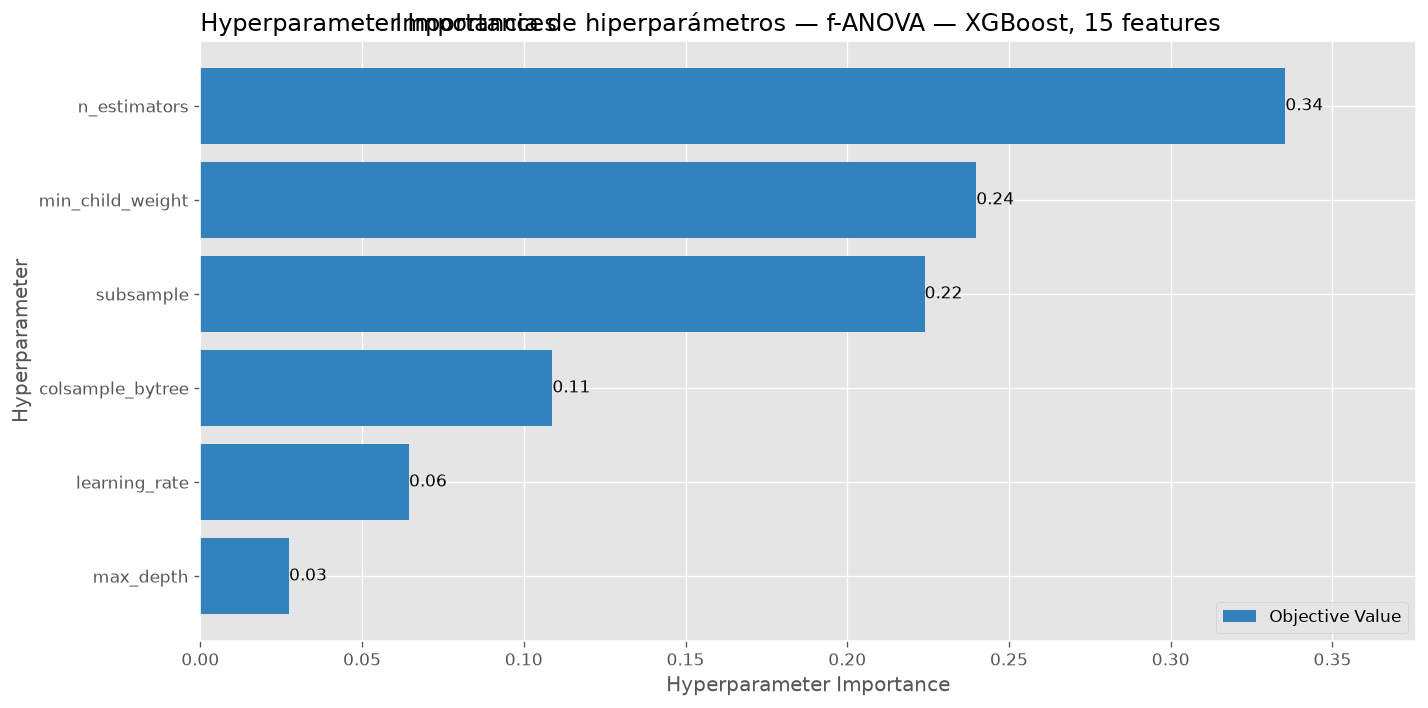

In [2]:
display(Image(filename=str(carpeta_png_15 / "importancia_hiperparametros_fanova.png")))


Las coordenadas paralelas guardadas relacionan hiperparámetros y MAE del estudio de 15 predictoras. Se muestra el PNG existente.


C:\Users\juanc\AppData\Local\Temp\ipykernel_26796\240063882.py:1: ExperimentalWarning: optuna.visualization.matplotlib._parallel_coordinate.plot_parallel_coordinate is experimental (supported from v2.2.0). The interface can change in the future.
  eje_paralelas = plot_parallel_coordinate(estudio_graficos_15)


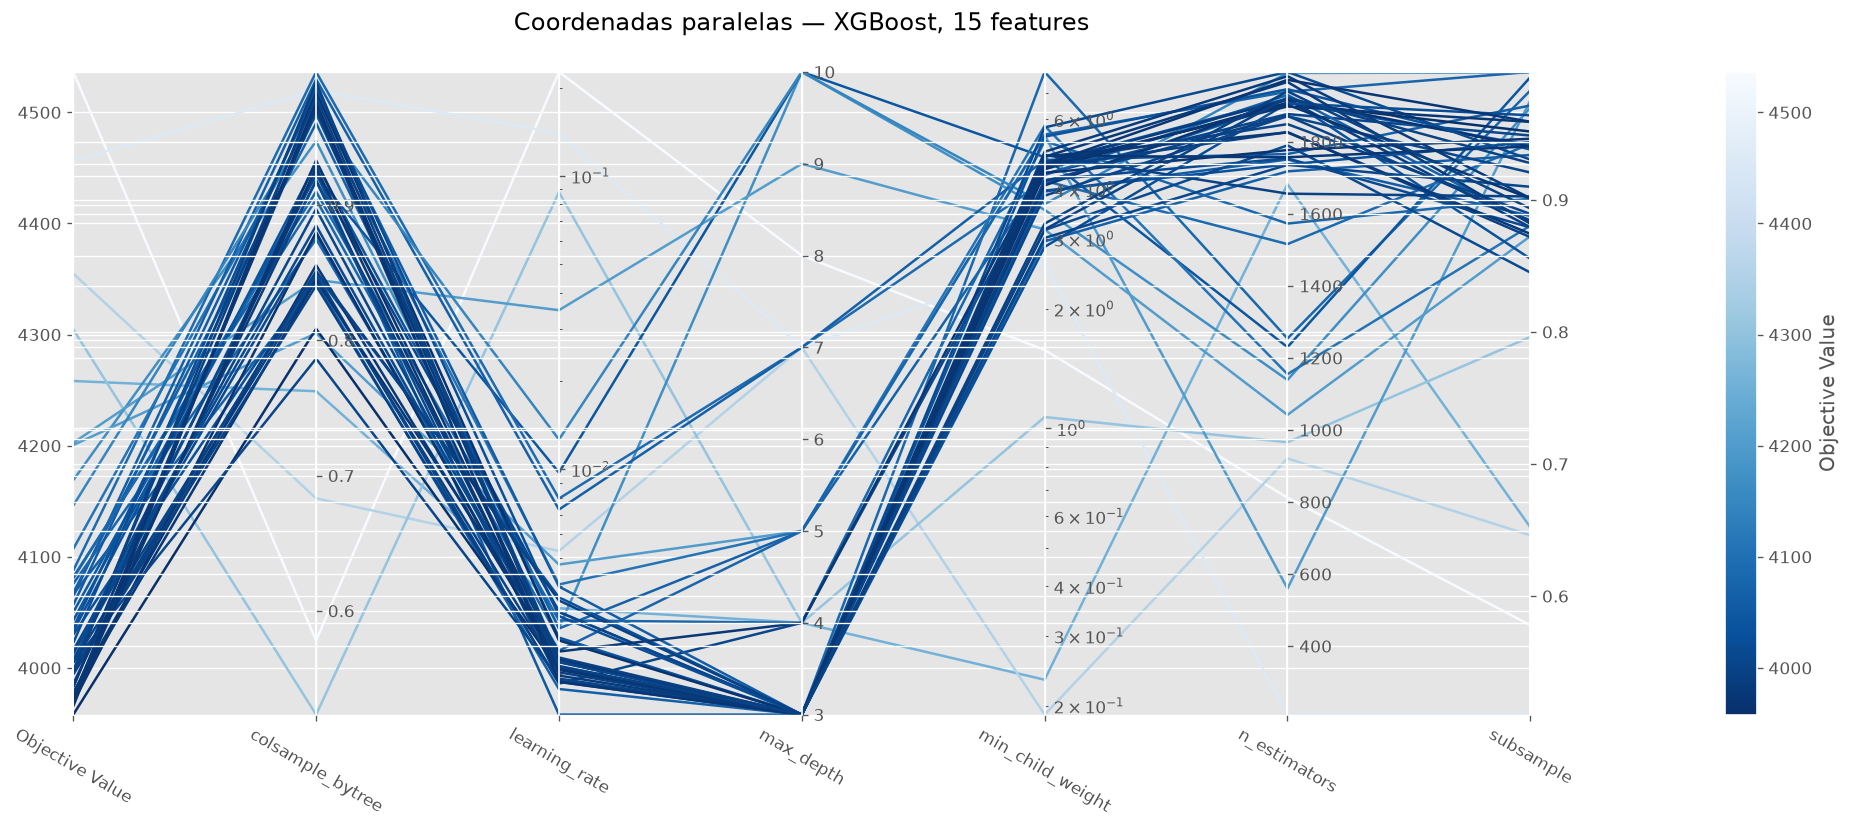

In [3]:
display(Image(filename=str(carpeta_png_15 / "coordenadas_paralelas.png")))


El historial guardado muestra el MAE de los trials completos y el mejor acumulado. La celda siguiente consulta el PNG sin abrir ni modificar SQLite.


C:\Users\juanc\AppData\Local\Temp\ipykernel_26796\105869753.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  eje_historial = plot_optimization_history(estudio_graficos_15)


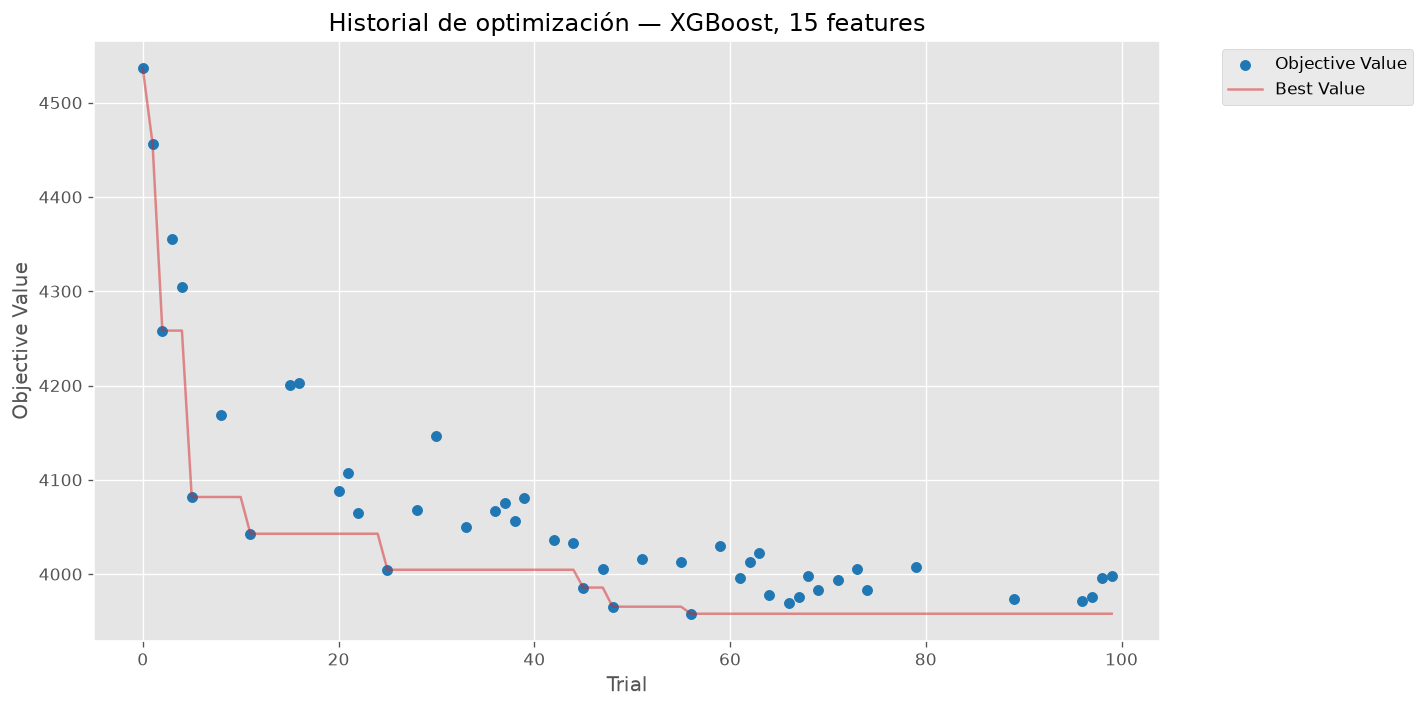

C:\Users\juanc\OneDrive\Documentos\tp_final_lab\modelado-xgboost\results\xgboost_15\graficos\coordenadas_paralelas.png
C:\Users\juanc\OneDrive\Documentos\tp_final_lab\modelado-xgboost\results\xgboost_15\graficos\historial_optimizacion.png
C:\Users\juanc\OneDrive\Documentos\tp_final_lab\modelado-xgboost\results\xgboost_15\graficos\importancia_hiperparametros_fanova.png


In [4]:
display(Image(filename=str(carpeta_png_15 / "historial_optimizacion.png")))


## 11. Lectura de los gráficos y definición de una segunda búsqueda

La importancia estimada mediante f-ANOVA concentra aproximadamente 34 % en `n_estimators`, 24 % en `min_child_weight` y 22 % en `subsample`. Estas importancias describen el espacio explorado y las configuraciones completadas; no son efectos causales ni garantizan la importancia fuera de ese espacio. Las coordenadas paralelas sugieren que los menores MAE se concentran en árboles poco profundos y cantidades altas de árboles. El historial mejoró hasta alrededor del ensayo 57 (trial 56, numerado desde cero) y luego se estabilizó cerca de 3.957,96 kW.

Estos resultados justifican explorar una zona más específica, sin afirmar que se encontró el óptimo definitivo. Para elegir los nuevos intervalos se revisan exclusivamente los diez mejores trials completos por MAE temporal de entrenamiento, sin utilizar la evaluación independiente de validación ya disponible.

Los diez mejores tienen `n_estimators` entre 1.757 y 1.982, `min_child_weight` entre 4,09035 y 4,97287, `subsample` entre 0,87423 y 0,95912 y `colsample_bytree` entre 0,80861 y 0,98423. Nueve de ellos usan profundidad 3. Se redondean hacia afuera los intervalos a 1.750–3.000 árboles, peso 4,0–5,0 (logarítmico), muestreo de filas 0,87–0,97 y muestreo de columnas 0,80–1,00. Los árboles se amplían hasta 3.000 porque los mejores valores están concentrados cerca del límite superior previo de 2.000.

Se fijan `learning_rate=0.0020702351473759497` y `max_depth=3`, tomados del mejor trial anterior. La segunda búsqueda tiene 60 trials totales y nombre `xgboost-temporal-15-features-refinado-v1`, con SQLite independiente. Reutiliza `TPESampler(seed=42)`, el mismo `MedianPruner`, cinco pliegues con `gap=1` y el MAE conjunto de las filas comunes. No usa early stopping ni ajusta un modelo definitivo. El ejecutor explícito es `python src/modelado_xgboost_15_refinado.py`; la celda siguiente solo consulta evidencia y no inicia trials.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
import sys

raiz_refinado = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz_refinado / "src"))
from auxiliar_functions import tabla_simple

carpeta_refinado = raiz_refinado / "results/xgboost_15_refinado"
resumen_refinado = json.loads((carpeta_refinado / "resumen.json").read_text(encoding="utf-8"))
comparacion_refinado = json.loads((carpeta_refinado / "comparacion.json").read_text(encoding="utf-8"))
print("Tabla 15. Los diez mejores trials del estudio previo, usados para definir los intervalos")
display(tabla_simple(pd.read_csv(carpeta_refinado / "top10_estudio_anterior.csv").set_index("trial")))
print("Tabla 16. Rangos optimizados en la segunda búsqueda")
display(tabla_simple(pd.DataFrame(comparacion_refinado["rangos"]).T))
print("Tabla 17. Estados de los 60 trials del estudio refinado")
display(tabla_simple(pd.Series(resumen_refinado["estados"], name="Trials").to_frame()))
print("Tabla 18. Mejores hiperparámetros provisionales y parámetros fijos")
display(tabla_simple(pd.Series({**comparacion_refinado["fijos"], **resumen_refinado["parametros_provisionales"]}, name="Valor").to_frame()))
print("Tabla 19. Comparación de MAE temporal de entrenamiento entre búsquedas")
display(tabla_simple(pd.DataFrame([{
    "MAE anterior": comparacion_refinado["mae_anterior"],
    "MAE nuevo": comparacion_refinado["mae_nuevo"],
    "Diferencia nuevo menos anterior": comparacion_refinado["diferencia_nuevo_menos_anterior"],
    "Mejora (%)": comparacion_refinado["mejora_porcentual"],
}])))
print("El signo de la diferencia indica mejora si es negativo y empeoramiento si es positivo.")

Tabla 15. Los diez mejores trials del estudio previo, usados para definir los intervalos


,mae,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree
trial,,,,,,,
56,3957.96,1908,0.00,3,4.49,0.95,0.81
48,3965.43,1918,0.00,3,4.09,0.94,0.98
66,3968.84,1777,0.00,3,4.40,0.95,0.88
96,3971.92,1903,0.00,3,4.55,0.90,0.93
89,3973.10,1972,0.00,3,4.62,0.96,0.98
67,3975.79,1898,0.00,4,4.61,0.96,0.84
97,3976.03,1757,0.00,3,4.86,0.94,0.93
64,3977.89,1826,0.00,3,4.84,0.87,0.86
69,3982.63,1966,0.00,3,4.83,0.88,0.97


Tabla 16. Rangos optimizados en la segunda búsqueda


,tipo,low,high,log
n_estimators,int,1750,3000,nan
min_child_weight,float,4.00,5.00,True
subsample,float,0.87,0.97,nan
colsample_bytree,float,0.80,1.00,nan


Tabla 17. Estados de los 60 trials del estudio refinado


,Trials
COMPLETE,45
PRUNED,15


Tabla 18. Mejores hiperparámetros provisionales y parámetros fijos


,Valor
reg_alpha,0
reg_lambda,1
gamma,0
objective,reg:squarederror
eval_metric,mae
tree_method,hist
random_state,42
n_jobs,1
learning_rate,0.00
max_depth,3


Tabla 19. Comparación de MAE temporal de entrenamiento entre búsquedas


,MAE anterior,MAE nuevo,Diferencia nuevo menos anterior,Mejora (%)
0,3957.96,3941.22,-16.74,0.42


El signo de la diferencia indica mejora si es negativo y empeoramiento si es positivo.


La comparación anterior corresponde al mismo procedimiento temporal dentro de entrenamiento. Ambos mínimos siguen siendo provisionales: la segunda búsqueda utiliza información de la primera y un presupuesto y espacio distintos, por lo que la diferencia observada no demuestra generalización ni un óptimo global. Las evaluaciones y figuras anteriores se conservan como evidencia histórica.

## 12. Configuración completa y curvas de MAE en validación independiente

Esta sección reemplaza el diagnóstico solicitado inicialmente sobre el último pliegue: ese diagnóstico no se ejecuta. Se fija la configuración completa del ganador de la segunda búsqueda combinando los cuatro parámetros optimizados con todos los parámetros fijos conservados, incluidos `learning_rate` y `max_depth`. Se ajusta un único XGBoost con las 830 filas de entrenamiento y sin early stopping.

Se proporcionan a `eval_set` el entrenamiento completo y las mismas 171 filas comunes de validación independiente. `evals_result()` registra el MAE de ambos conjuntos desde el primer árbol hasta el `n_estimators` elegido por Optuna. La validación no controla el ajuste, la cantidad de árboles ni los hiperparámetros. Se conservan las curvas y las predicciones, se registra la evaluación con el commit real y se exporta el gráfico en PNG. La celda es autónoma y reutiliza la evidencia si ya existe, sin repetir el entrenamiento. No se utiliza prueba ni se entrena un modelo de producción. El gráfico queda sin interpretación sobre sobreajuste.
En la versión de consulta previa al PR, la celda siguiente lee únicamente evaluacion.json y el PNG ya guardados; no invoca el evaluador ni repite el ajuste.


Tabla 20. Configuración completa de XGBoost fijada antes de evaluar validación


,Valor
reg_alpha,0
reg_lambda,1
gamma,0
objective,reg:squarederror
eval_metric,mae
tree_method,hist
random_state,42
n_jobs,1
learning_rate,0.00
max_depth,3


Tabla 21. MAE de validación independiente del ganador refinado


,Trial,Filas de entrenamiento,Filas comunes de validación,Árboles entrenados,MAE de validación (kW)
0,49,830,171,1994,2229.22


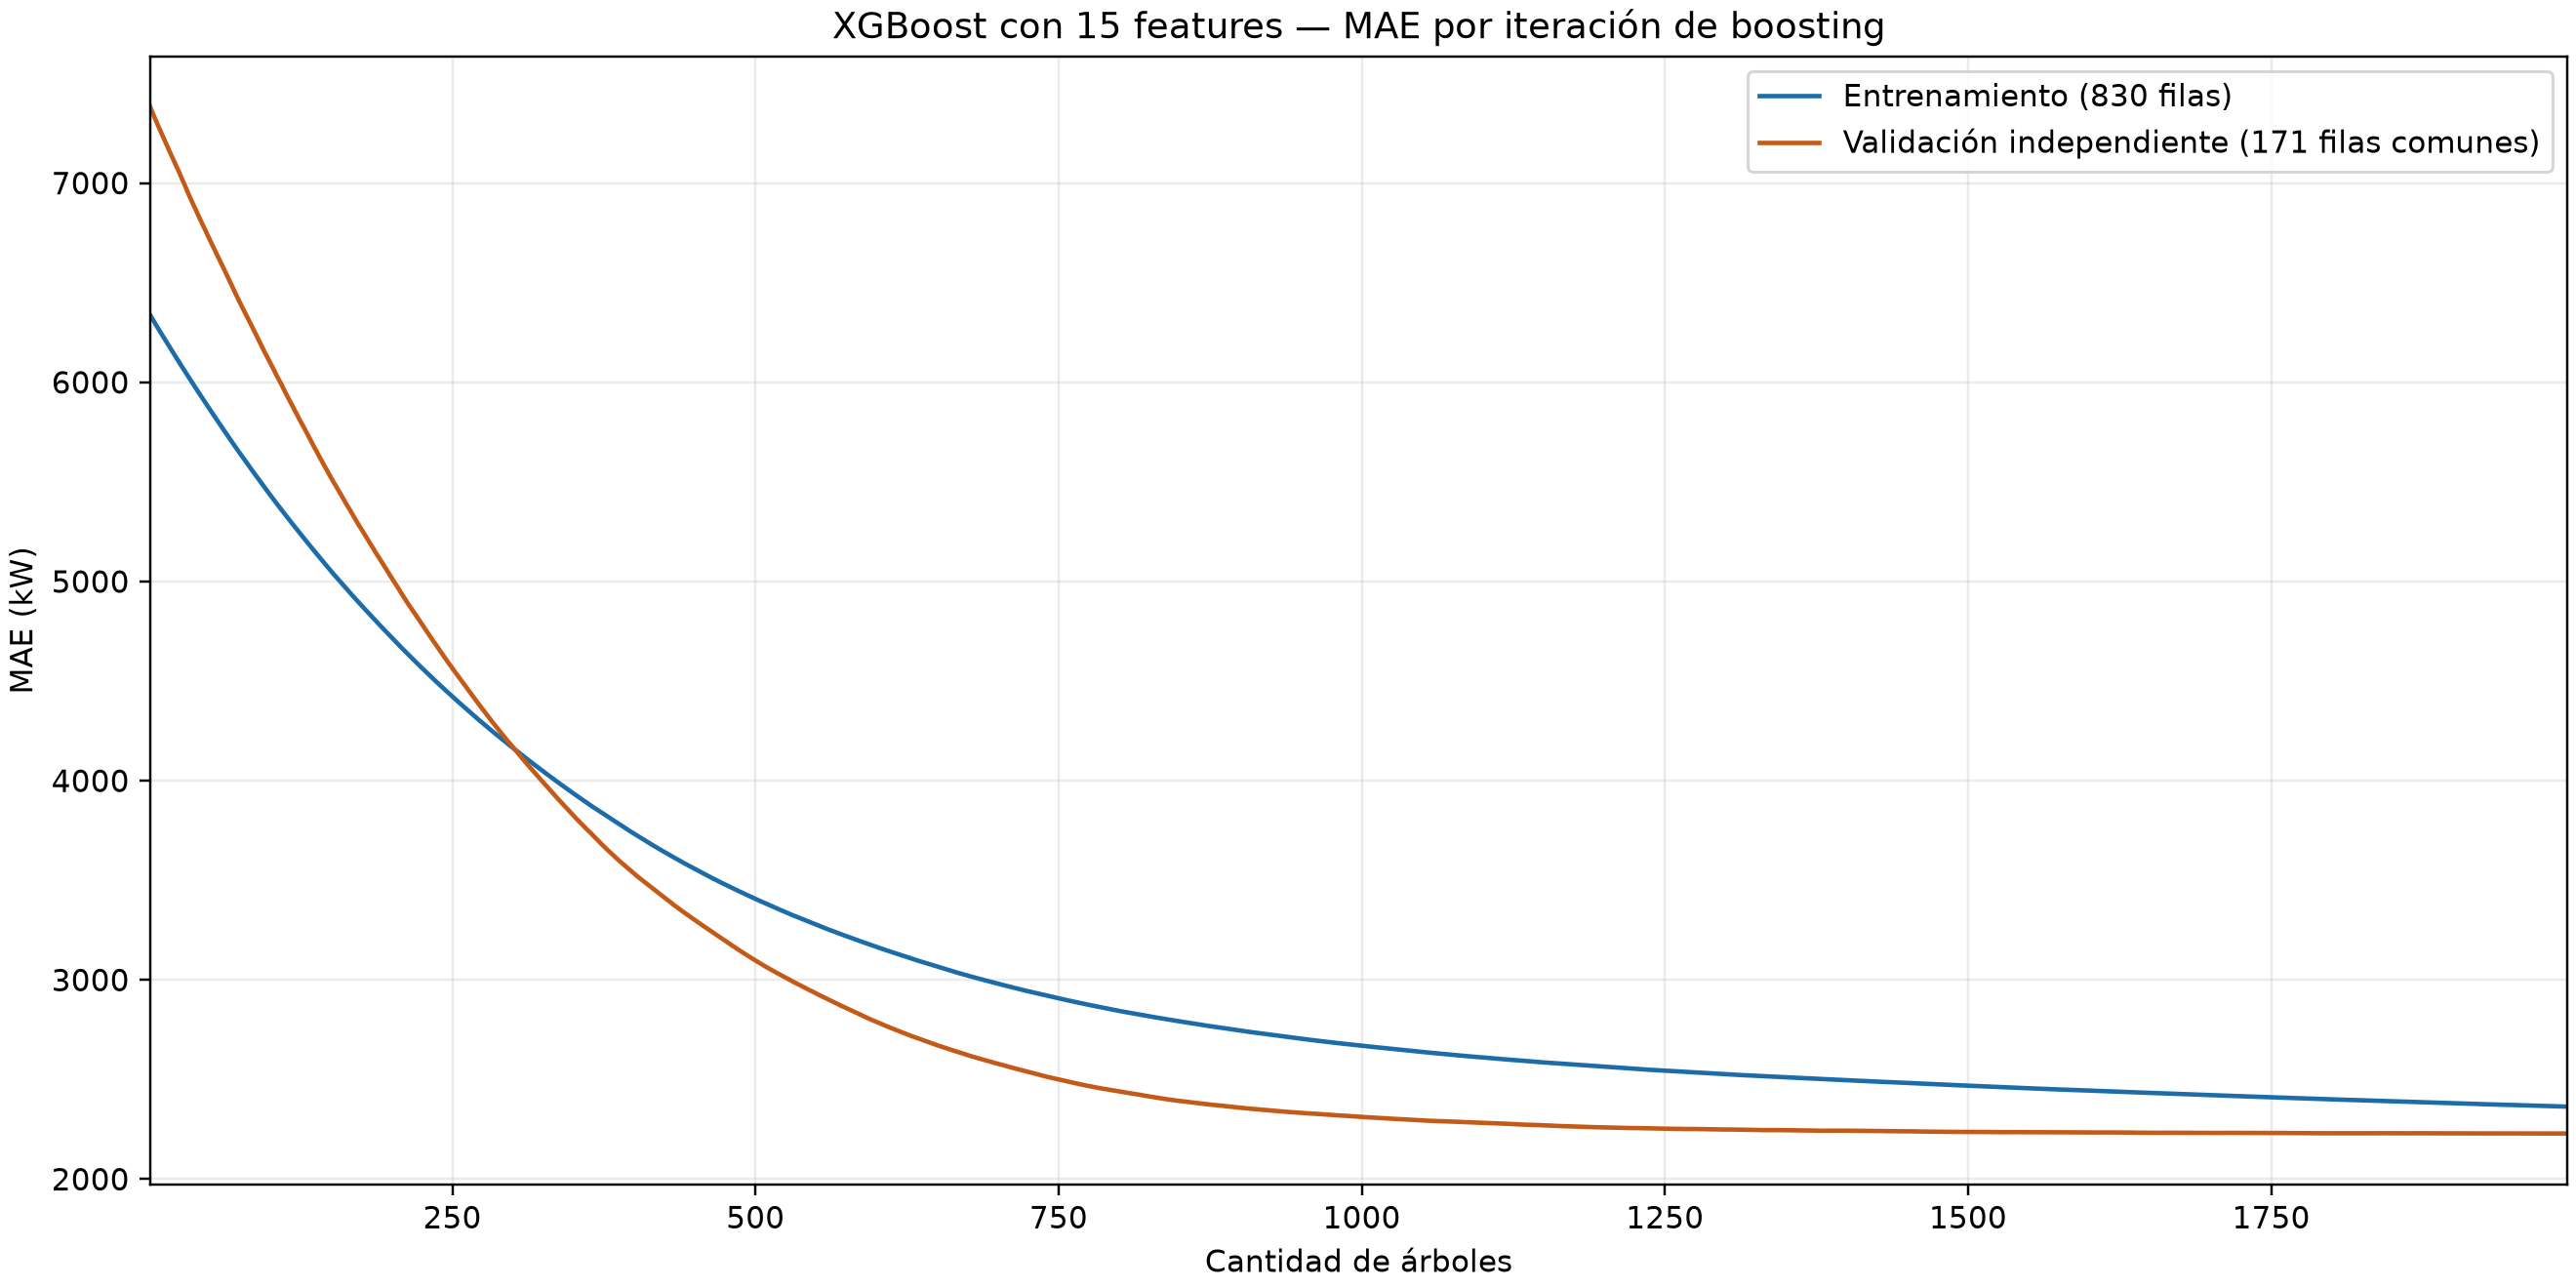

In [2]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

raiz_curvas = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz_curvas / "src"))
from auxiliar_functions import tabla_simple

resultado_curvas = json.loads((raiz_curvas / "results/xgboost_15_refinado_validacion/evaluacion.json").read_text(encoding="utf-8"))
print("Tabla 20. Configuración completa de XGBoost fijada antes de evaluar validación")
display(tabla_simple(pd.Series(resultado_curvas["configuracion_completa"], name="Valor").to_frame()))
print("Tabla 21. MAE de validación independiente del ganador refinado")
display(tabla_simple(pd.DataFrame([{
    "Trial": resultado_curvas["trial"], "Filas de entrenamiento": resultado_curvas["filas_ajuste"],
    "Filas comunes de validación": resultado_curvas["filas_validacion"],
    "Árboles entrenados": resultado_curvas["arboles_entrenados"],
    "MAE de validación (kW)": resultado_curvas["registro"]["mae"],
}])))
display(Image(filename=str(raiz_curvas / resultado_curvas["png"])))

## 13. Diagnóstico de validación desde predicciones archivadas

Esta sección es autónoma: se ejecutó únicamente este apéndice con cervecera_env,
sin ejecutar las celdas históricas anteriores. Lee resultados de
results/xgboost_diagnostico_validacion, sin abrir el dataset ni importar estimadores.
La sección 3.3 de la consigna pide comparar validación y analizar predicciones y
residuos; la importancia de variables se reserva al mejor modelo global.
Se mantienen las quince variables oficiales y los resultados históricos intactos.

Primero se recuperan las métricas registradas y los parámetros completos. La
validación de ambas búsquedas contiene las mismas filas, y los baselines se
comparan sobre ese mismo conjunto. La tabla de residuos usa real menos predicho:
valores positivos son subestimaciones y negativos, sobreestimaciones.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

raiz_diagnostico = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz_diagnostico / "src"))
from diagnostico_xgboost import huella

carpeta_diagnostico = raiz_diagnostico / "results/xgboost_diagnostico_validacion"
verificacion_diagnostico = json.loads((carpeta_diagnostico / "verificacion.json").read_text(encoding="utf-8"))
resumen_diagnostico = pd.read_csv(carpeta_diagnostico / "resumen_residuos.csv")
print("Tabla 22. Métricas registradas de validación y baselines sobre las mismas filas")
display(pd.read_csv(carpeta_diagnostico / "comparacion_validacion.csv").round(4))
print("Tabla 23. Parámetros completos de los ganadores de ambas búsquedas")
display(pd.read_csv(carpeta_diagnostico / "hiperparametros.csv").pivot(index="hiperparametro", columns="experimento", values="valor"))
print("Tabla 24. Espacios de búsqueda conservados en los contratos originales")
display(pd.read_csv(carpeta_diagnostico / "espacios_busqueda.csv"))

Tabla 22. Métricas registradas de validación y baselines sobre las mismas filas


,experimento,filas,mae,rmse,r2
0,inicial_15,171,2221.7606,2844.3074,0.4644
1,refinado_15,171,2229.2246,2853.1306,0.4611
2,persistencia,171,2668.3275,3319.4336,0.2705
3,media_movil,171,2497.6536,3368.0752,0.2490


Tabla 23. Parámetros completos de los ganadores de ambas búsquedas


experimento,inicial_15,refinado_15
hiperparametro,,
colsample_bytree,0.8086142929785466,0.89176387518403
eval_metric,mae,mae
gamma,0,0
learning_rate,0.0020702351473759497,0.0020702351473759497
max_depth,3,3
min_child_weight,4.49480789319248,4.632253473557002
n_estimators,1908,1994
n_jobs,1,1
objective,reg:squarederror,reg:squarederror


Tabla 24. Espacios de búsqueda conservados en los contratos originales


,experimento,hiperparametro,tipo,low,high,log
0,inicial_15,n_estimators,int,100.000,2000.00,NaN
1,inicial_15,learning_rate,float,0.001,0.30,True
2,inicial_15,max_depth,int,3.000,10.00,NaN
3,inicial_15,min_child_weight,float,0.100,10.00,True
4,inicial_15,subsample,float,0.500,1.00,NaN
5,inicial_15,colsample_bytree,float,0.500,1.00,NaN
6,refinado_15,n_estimators,int,1750.000,3000.00,NaN
7,refinado_15,min_child_weight,float,4.000,5.00,True
8,refinado_15,subsample,float,0.870,0.97,NaN
9,refinado_15,colsample_bytree,float,0.800,1.00,NaN


## 14. Predicciones y distribución de residuos

La comparación de predicción frente a real incluye la diagonal de predicción
exacta. La serie temporal conserva las fechas rotuladas de emisión D, cuyo objetivo
es el bloque siguiente. Las líneas unen solo filas disponibles y no interpolan los
días ausentes; las fechas no se utilizan como clave de unión. Se muestran ambos
experimentos con escalas comparables, sin recalibrar ni alterar las predicciones.

Figura. Predicción frente a real


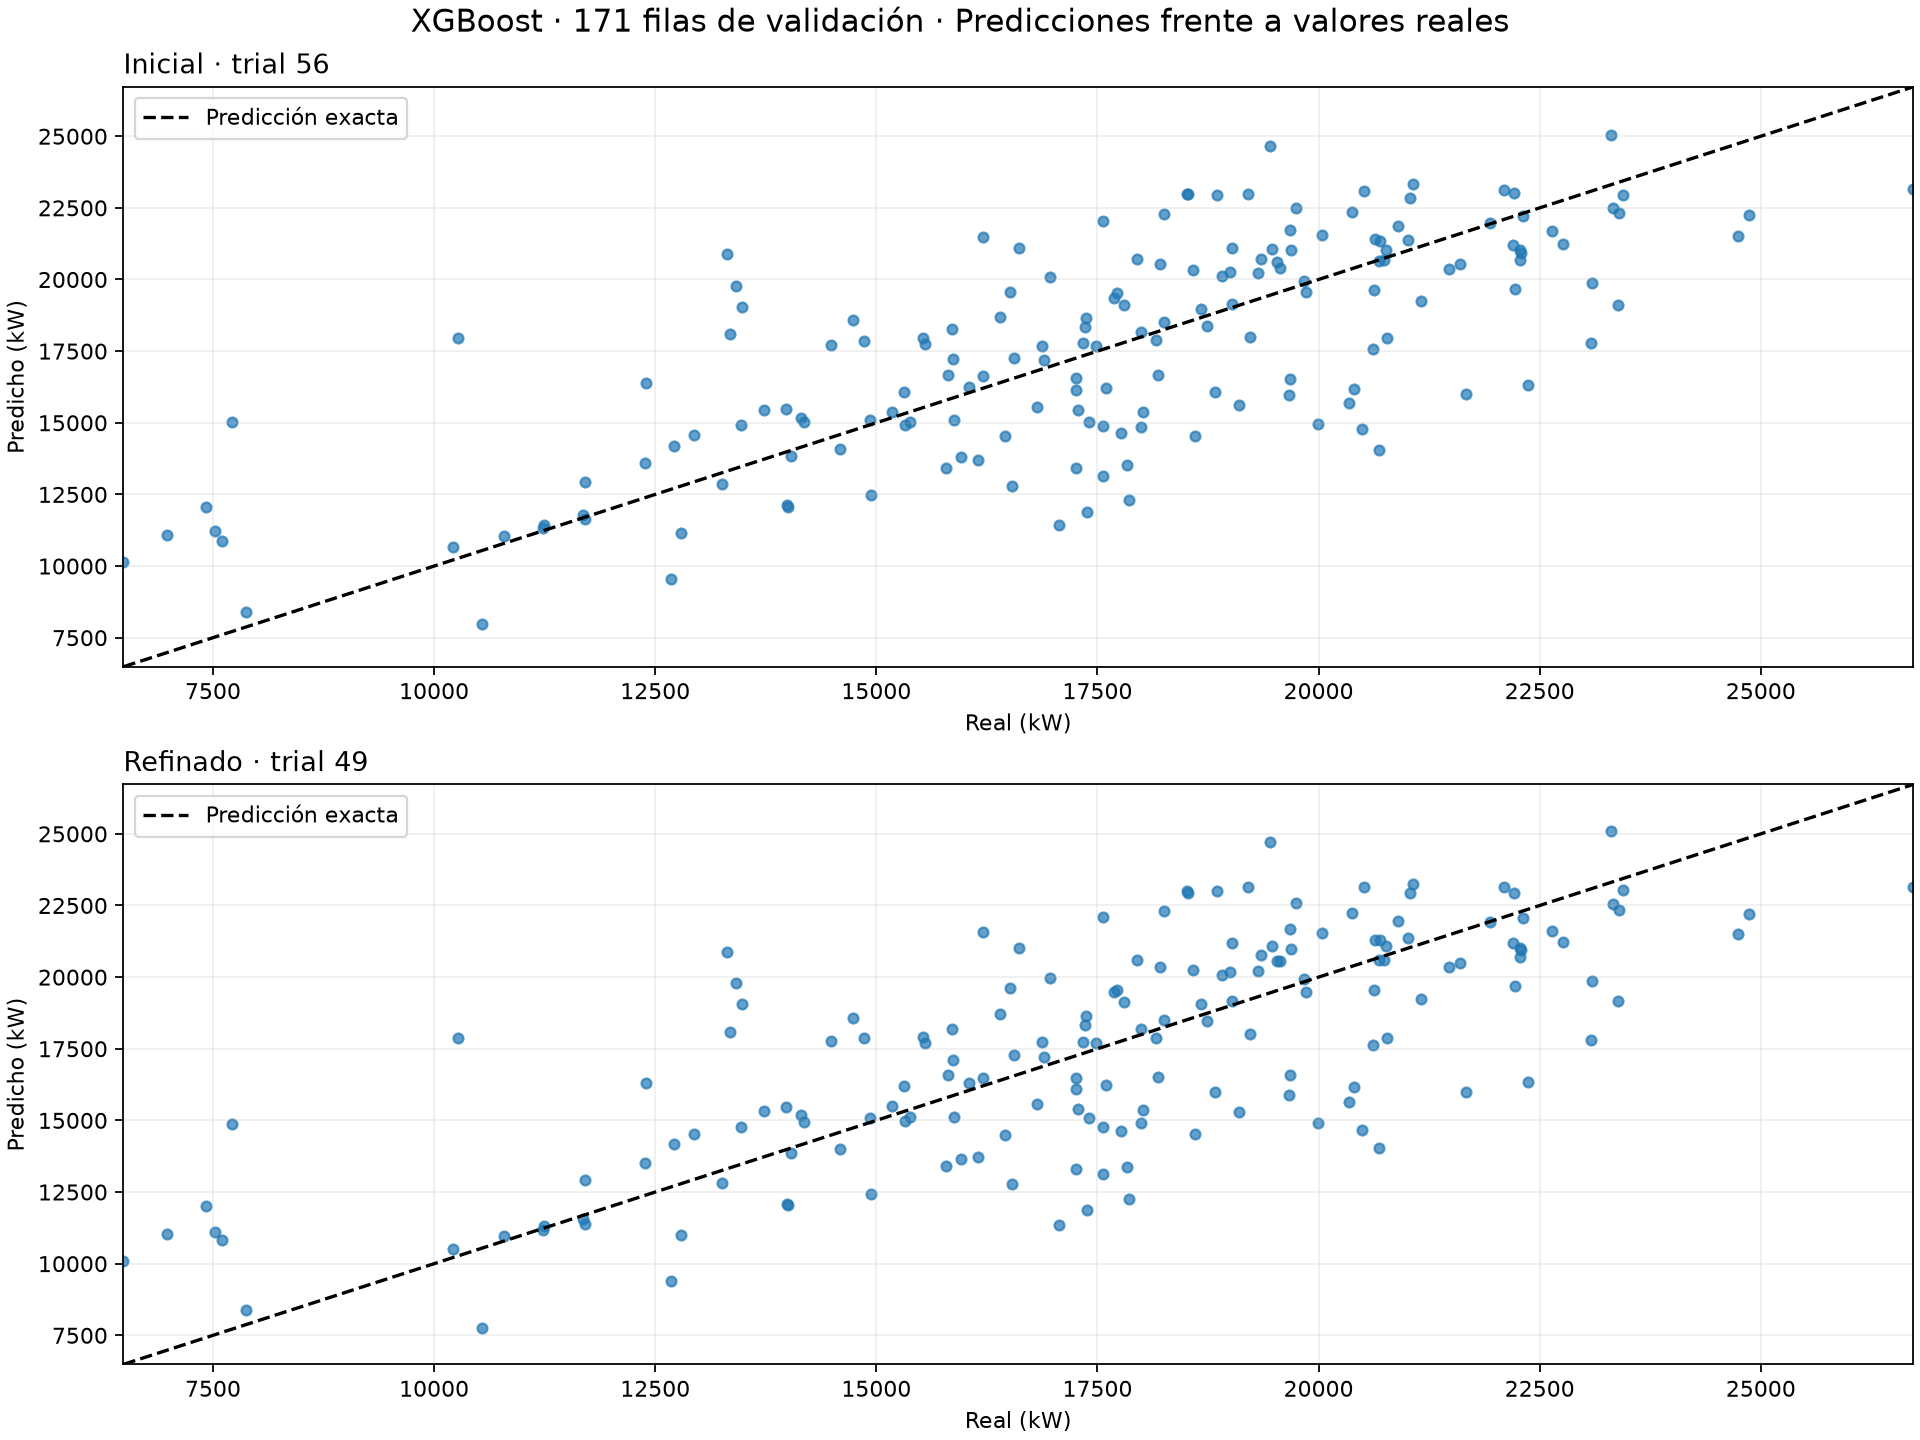

In [2]:
print("Figura. Predicción frente a real")
display(Image(filename=str(carpeta_diagnostico / "prediccion_vs_real.png")))

La figura siguiente complementa la comparación con el orden temporal y conserva todas las observaciones disponibles.

Figura. Real y predicción por fecha de emisión


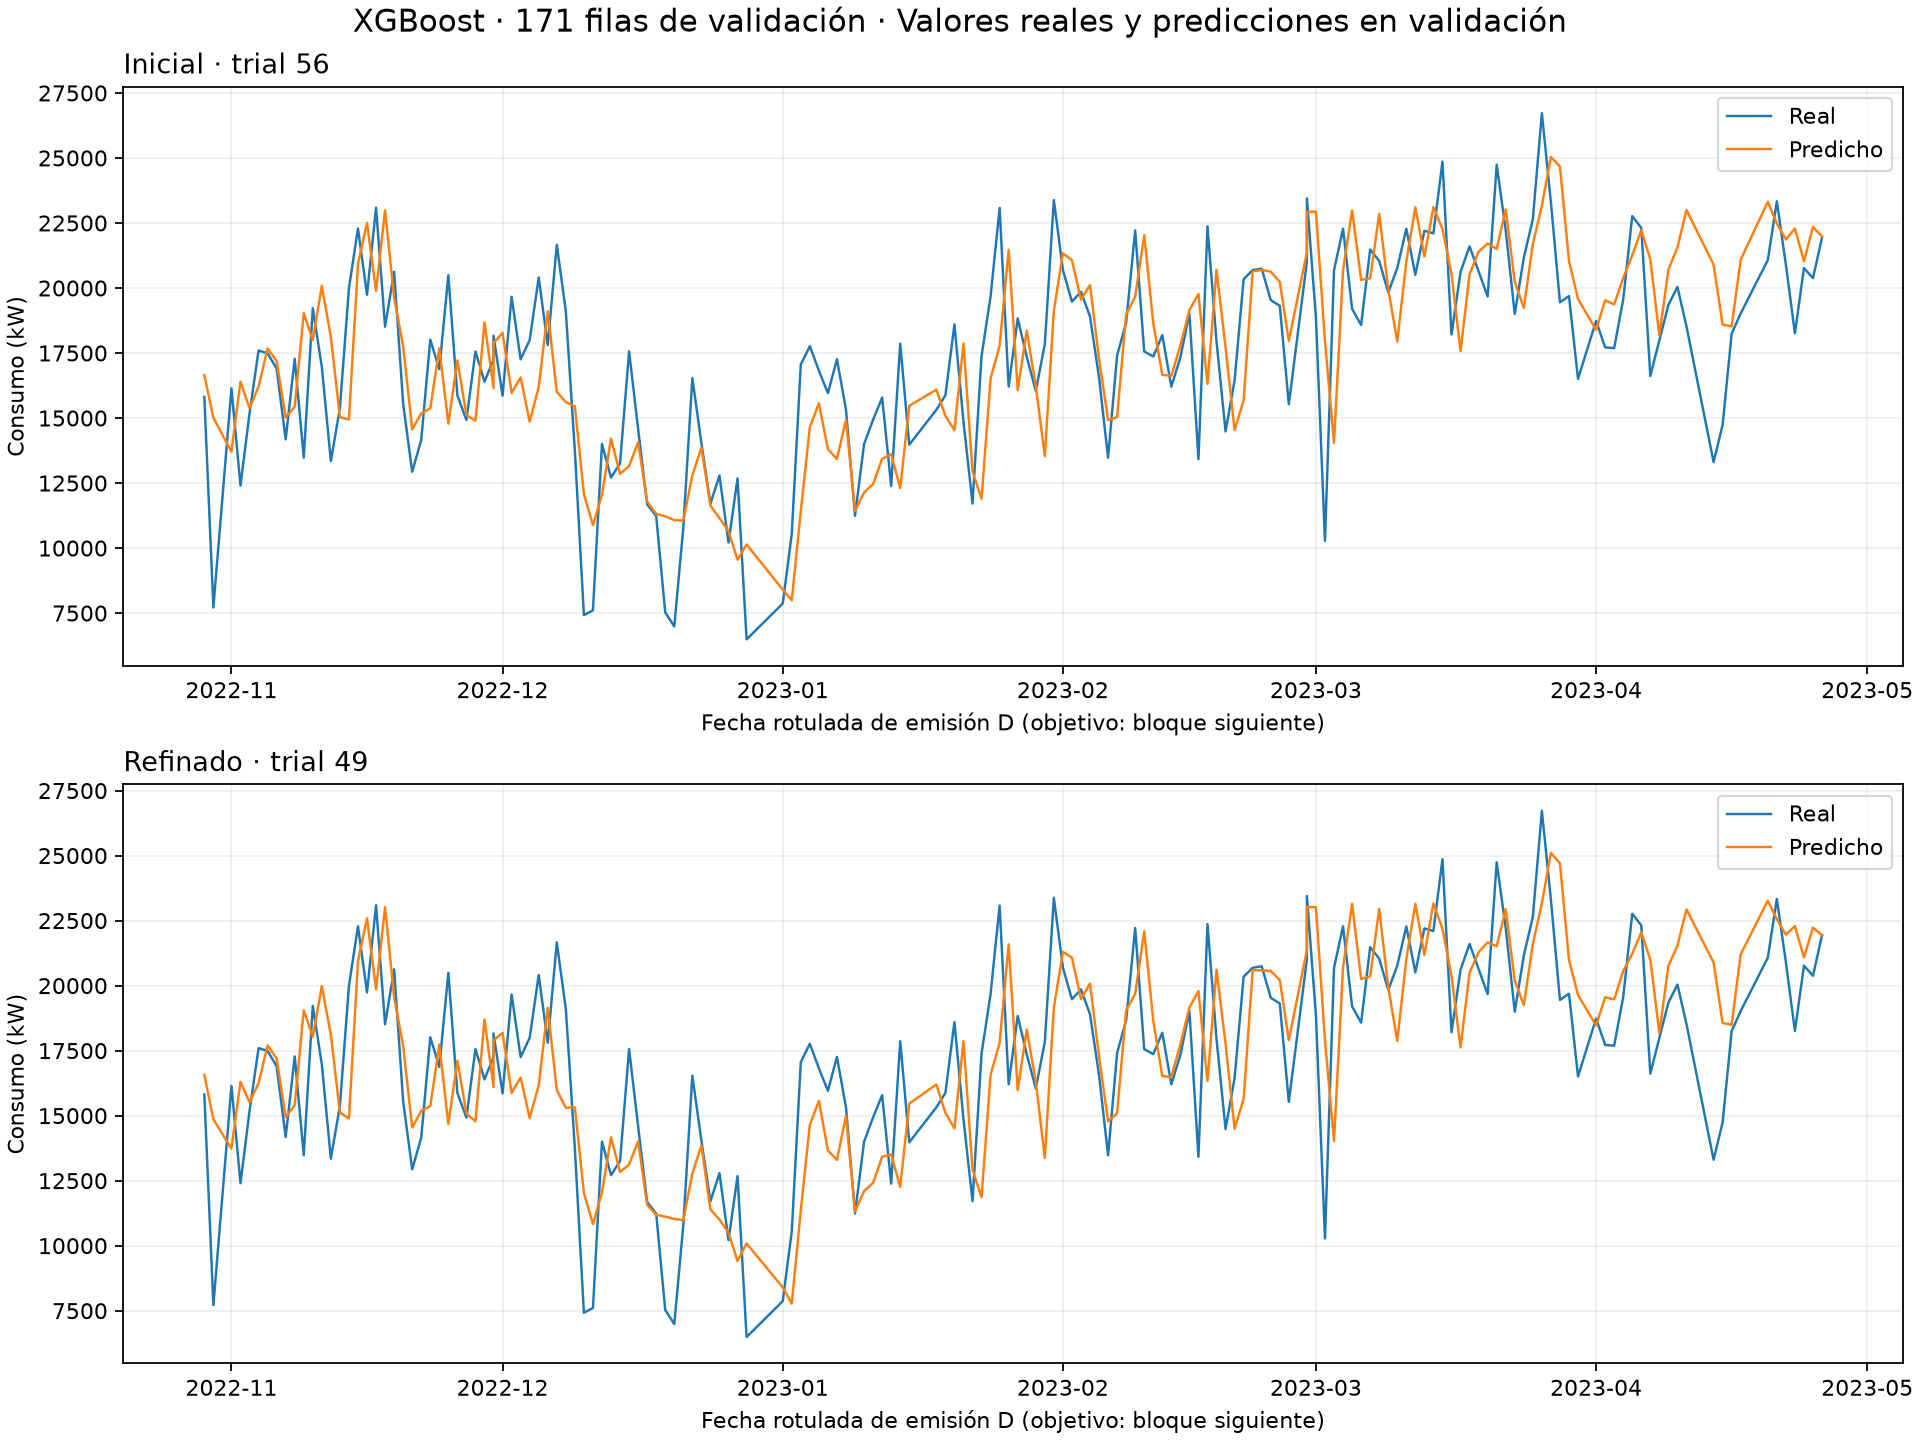

In [3]:
print("Figura. Real y predicción por fecha de emisión")
display(Image(filename=str(carpeta_diagnostico / "predicciones_temporales.png")))

El histograma siguiente muestra el signo y la magnitud de los errores, con referencias en cero y en su media. La forma visual no constituye una prueba de normalidad.

Figura. Distribución de residuos


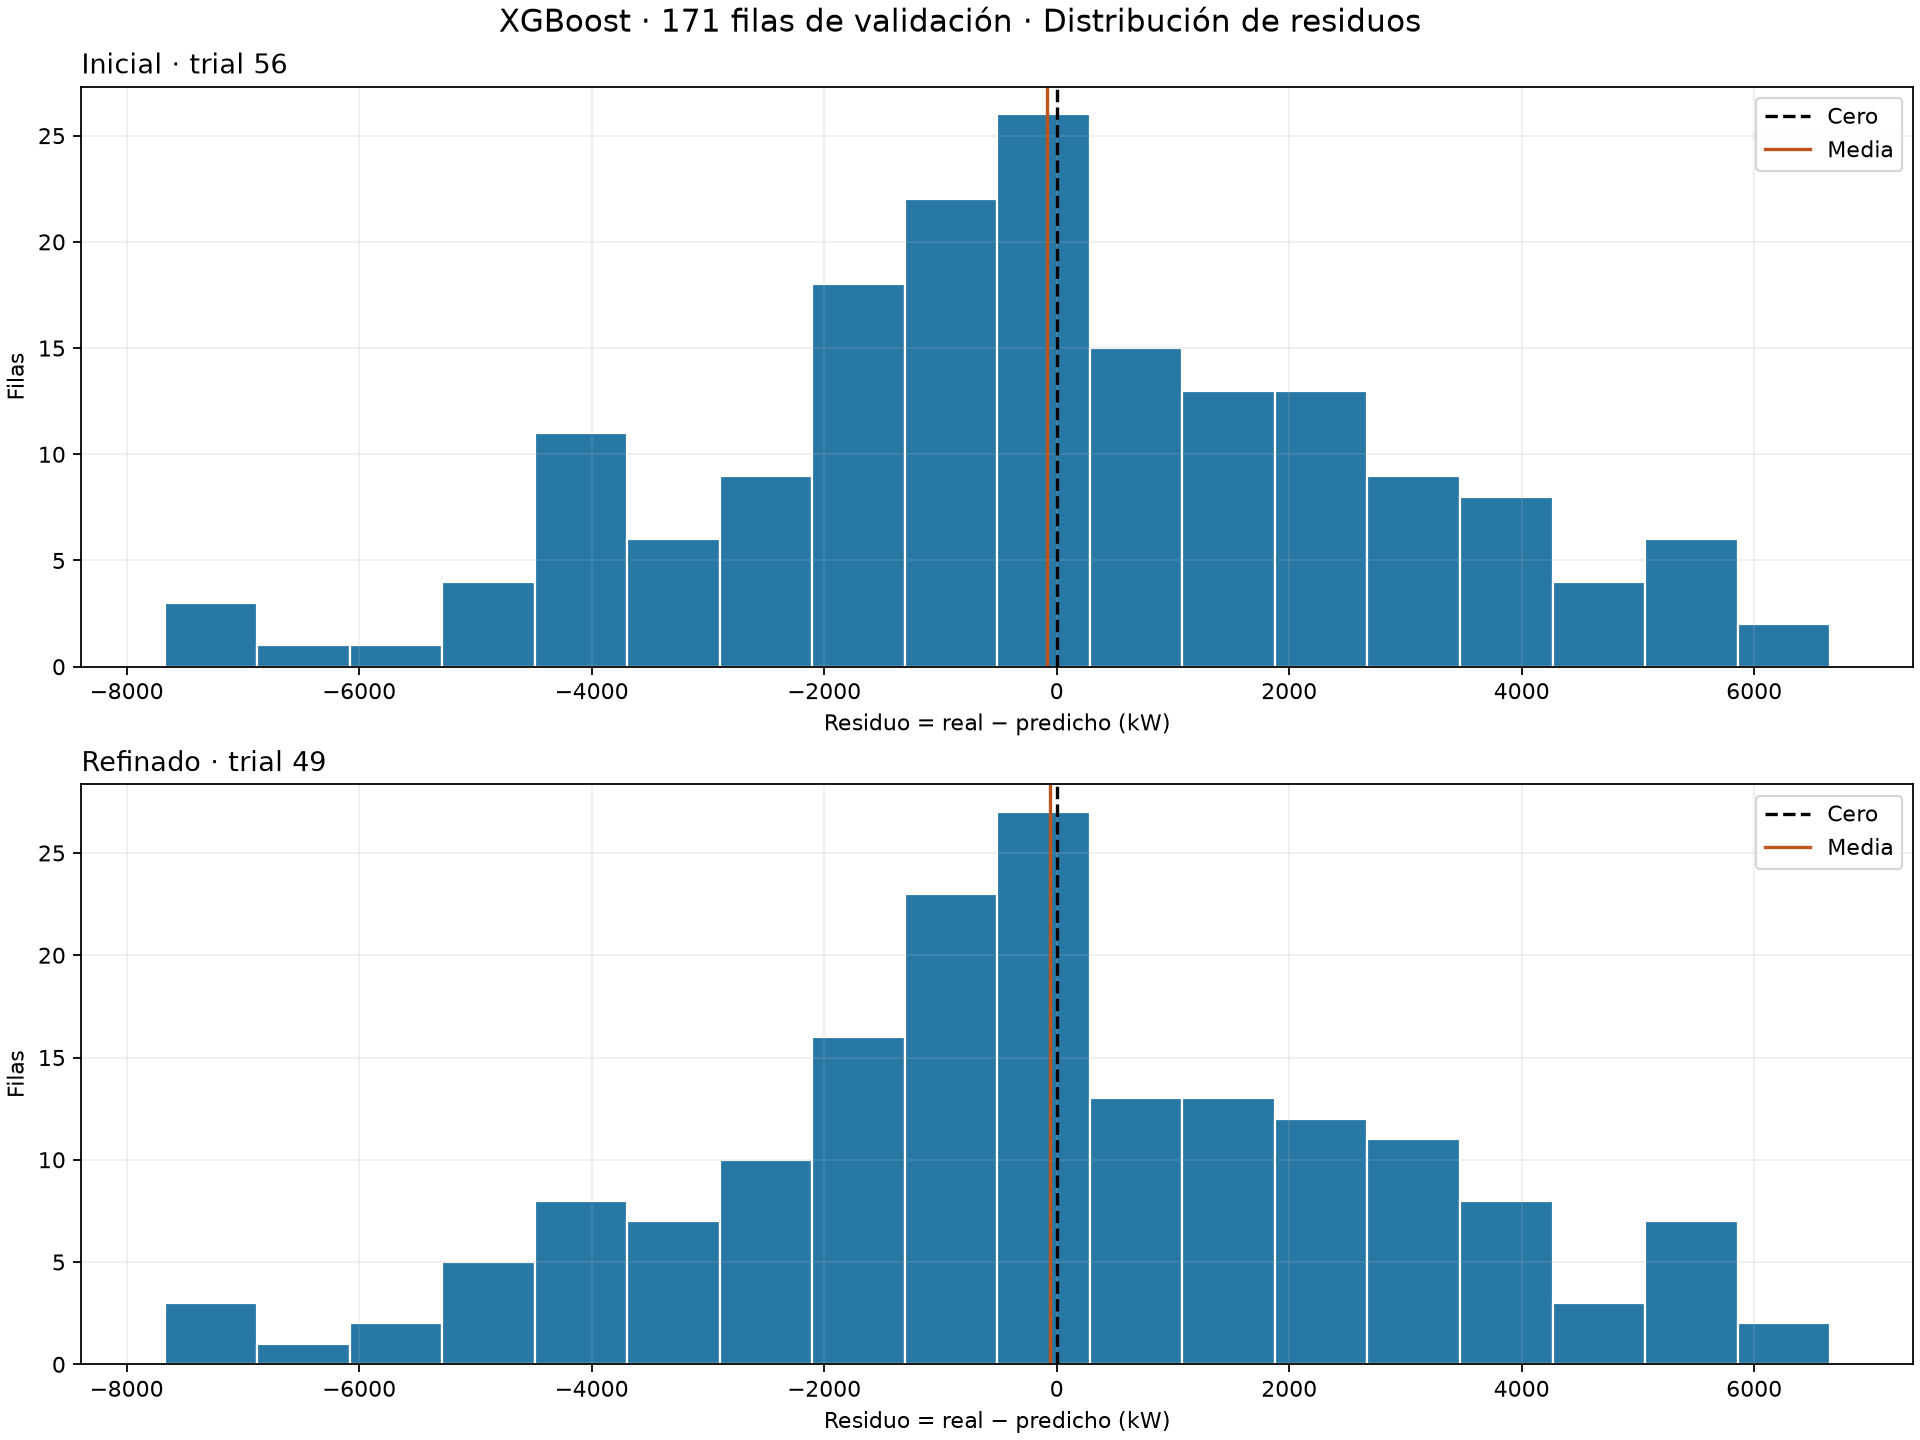

In [4]:
print("Figura. Distribución de residuos")
display(Image(filename=str(carpeta_diagnostico / "distribucion_residuos.png")))

La tabla siguiente distingue el sesgo promedio de la dispersión y las colas del error. Las métricas terminadas en registrado provienen del registro histórico; las demás se calculan sobre los decimales del CSV. La recuperación de float32 verifica la coincidencia con el log sin cambiar los CSV originales.

In [5]:
print("Tabla 25. Resumen descriptivo de residuos y conciliación de precisión")
display(resumen_diagnostico.round(5))

Tabla 25. Resumen descriptivo de residuos y conciliación de precisión


,experimento,trial,mae_cv,mae,rmse,r2,filas,sesgo_real_menos_predicho,mediana_residuo,desvio_residuo,...,p95_residuo,p95_error_absoluto,max_error_absoluto,subestimaciones,sobreestimaciones,fraccion_error_top10,mae_registrado,rmse_registrado,r2_registrado,max_delta_prediccion_float32
0,inicial_15,56,3957.96000,2221.76065,2844.30744,0.46441,171,-79.92977,-194.497,2851.53418,...,4850.5920,5595.6775,7672.621,76,95,0.16893,2221.76063,2844.30742,0.46441,0.00094
1,refinado_15,49,3941.22332,2229.22464,2853.13055,0.46108,171,-53.41455,-213.537,2861.00830,...,4897.9425,5641.0120,7606.938,79,92,0.16839,2229.22463,2853.13057,0.46108,0.00086


## 15. Residuos frente a predicciones, evolución y errores mayores

Los residuos frente a predicciones permiten examinar si el error cambia según el
nivel estimado. La evolución temporal y las tablas mensuales muestran patrones
que pueden cancelarse en el sesgo global. Se informa la cantidad de filas por mes
para no dar el mismo peso interpretativo a meses completos y parciales.

Figura. Residuos frente a predicciones


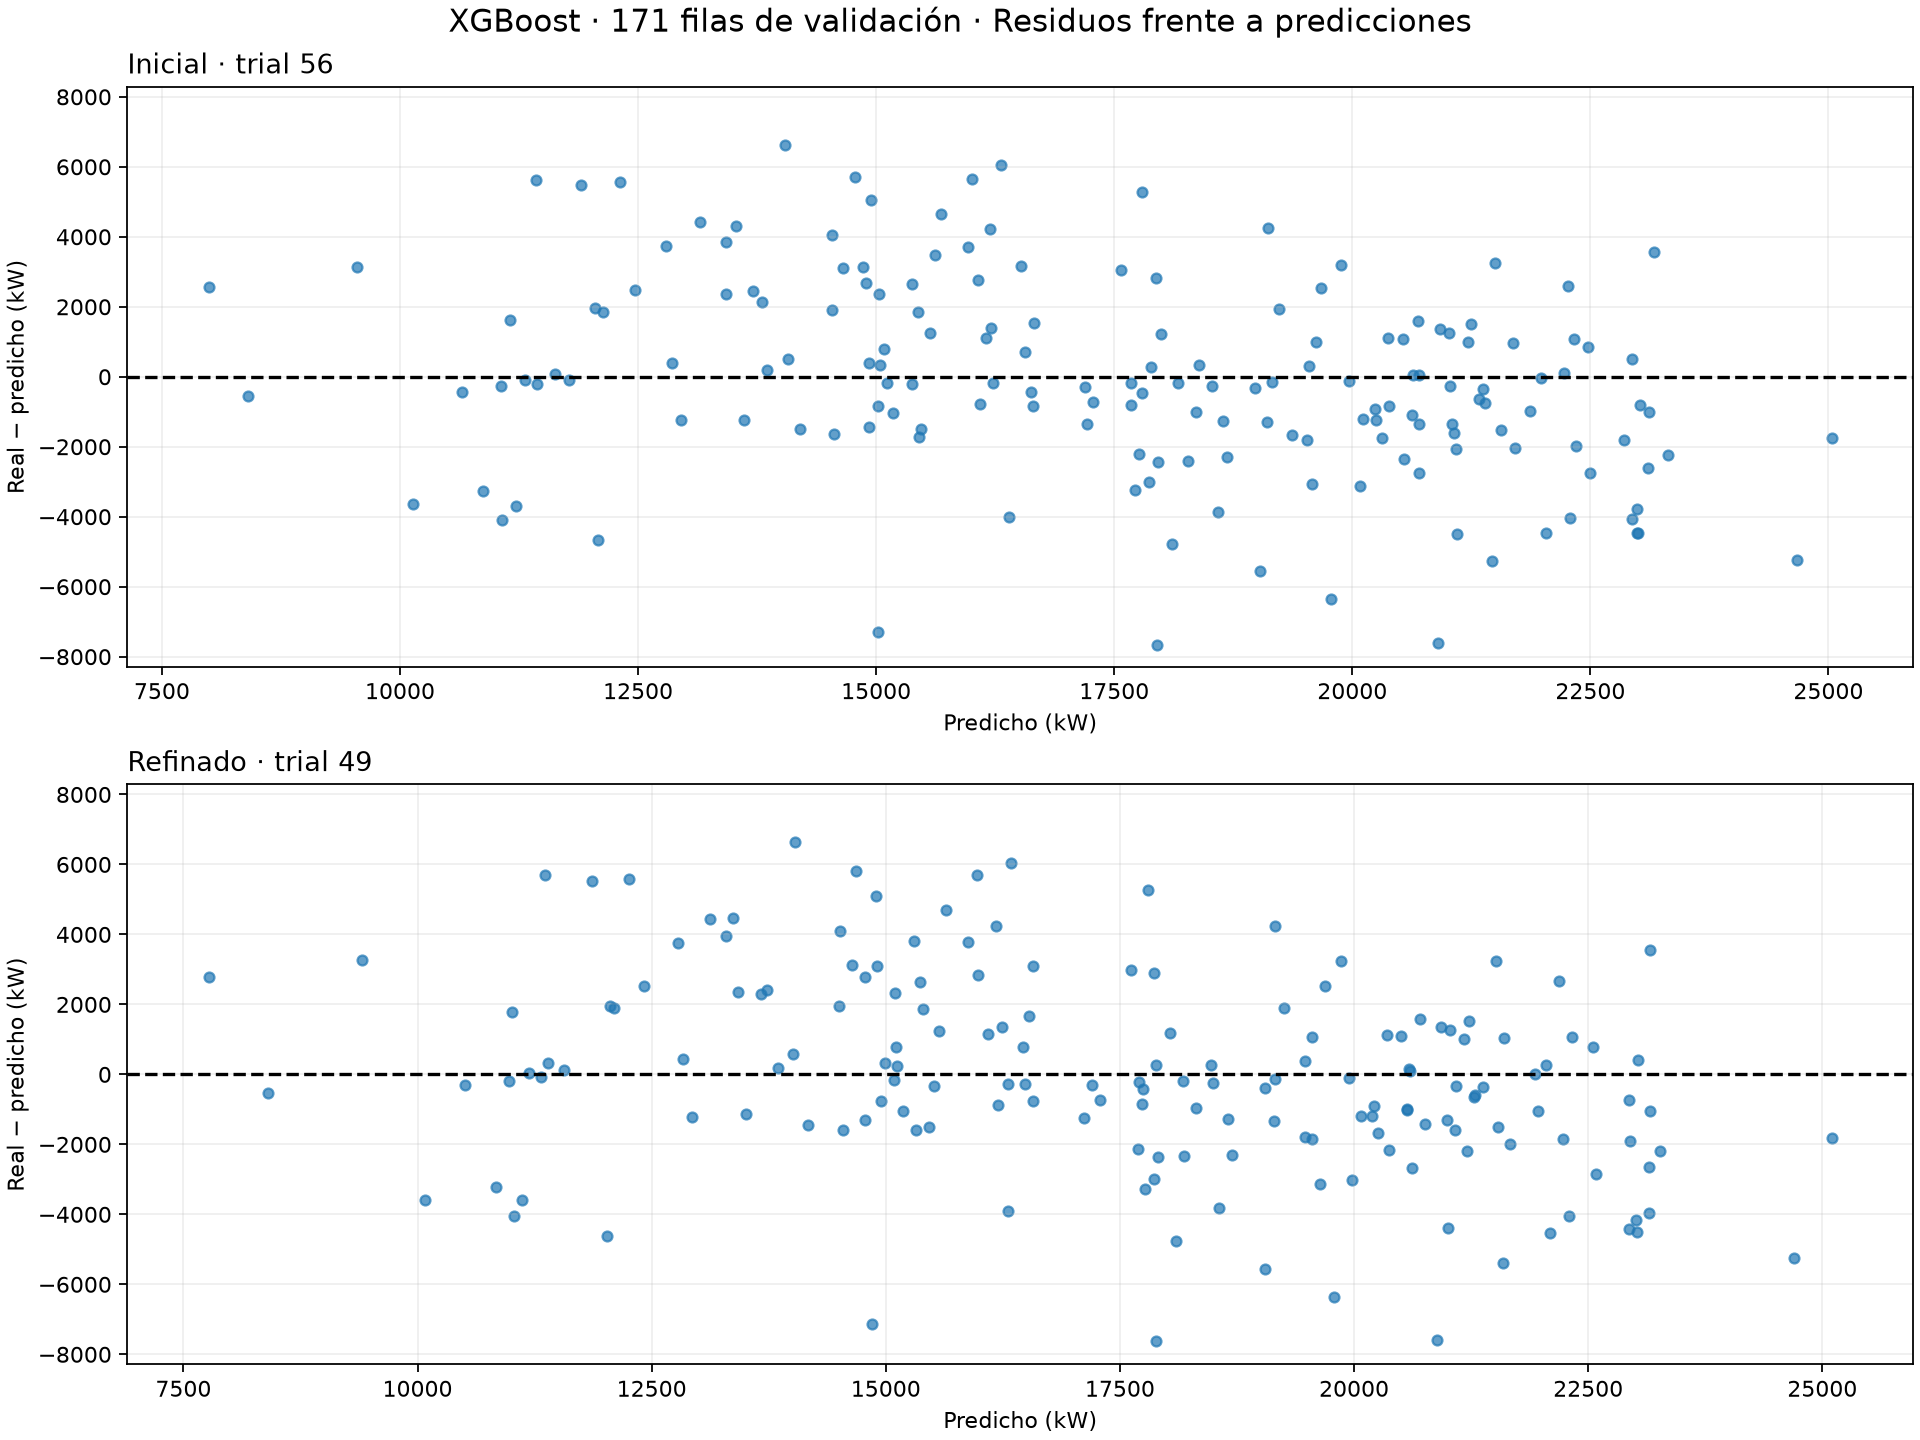

In [6]:
print("Figura. Residuos frente a predicciones")
display(Image(filename=str(carpeta_diagnostico / "residuos_vs_predicciones.png")))

La figura temporal conserva la misma convención de signo y las mismas escalas para ambas búsquedas. No se atribuye un patrón a una causa operativa sin evidencia adicional.

Figura. Evolución temporal de residuos


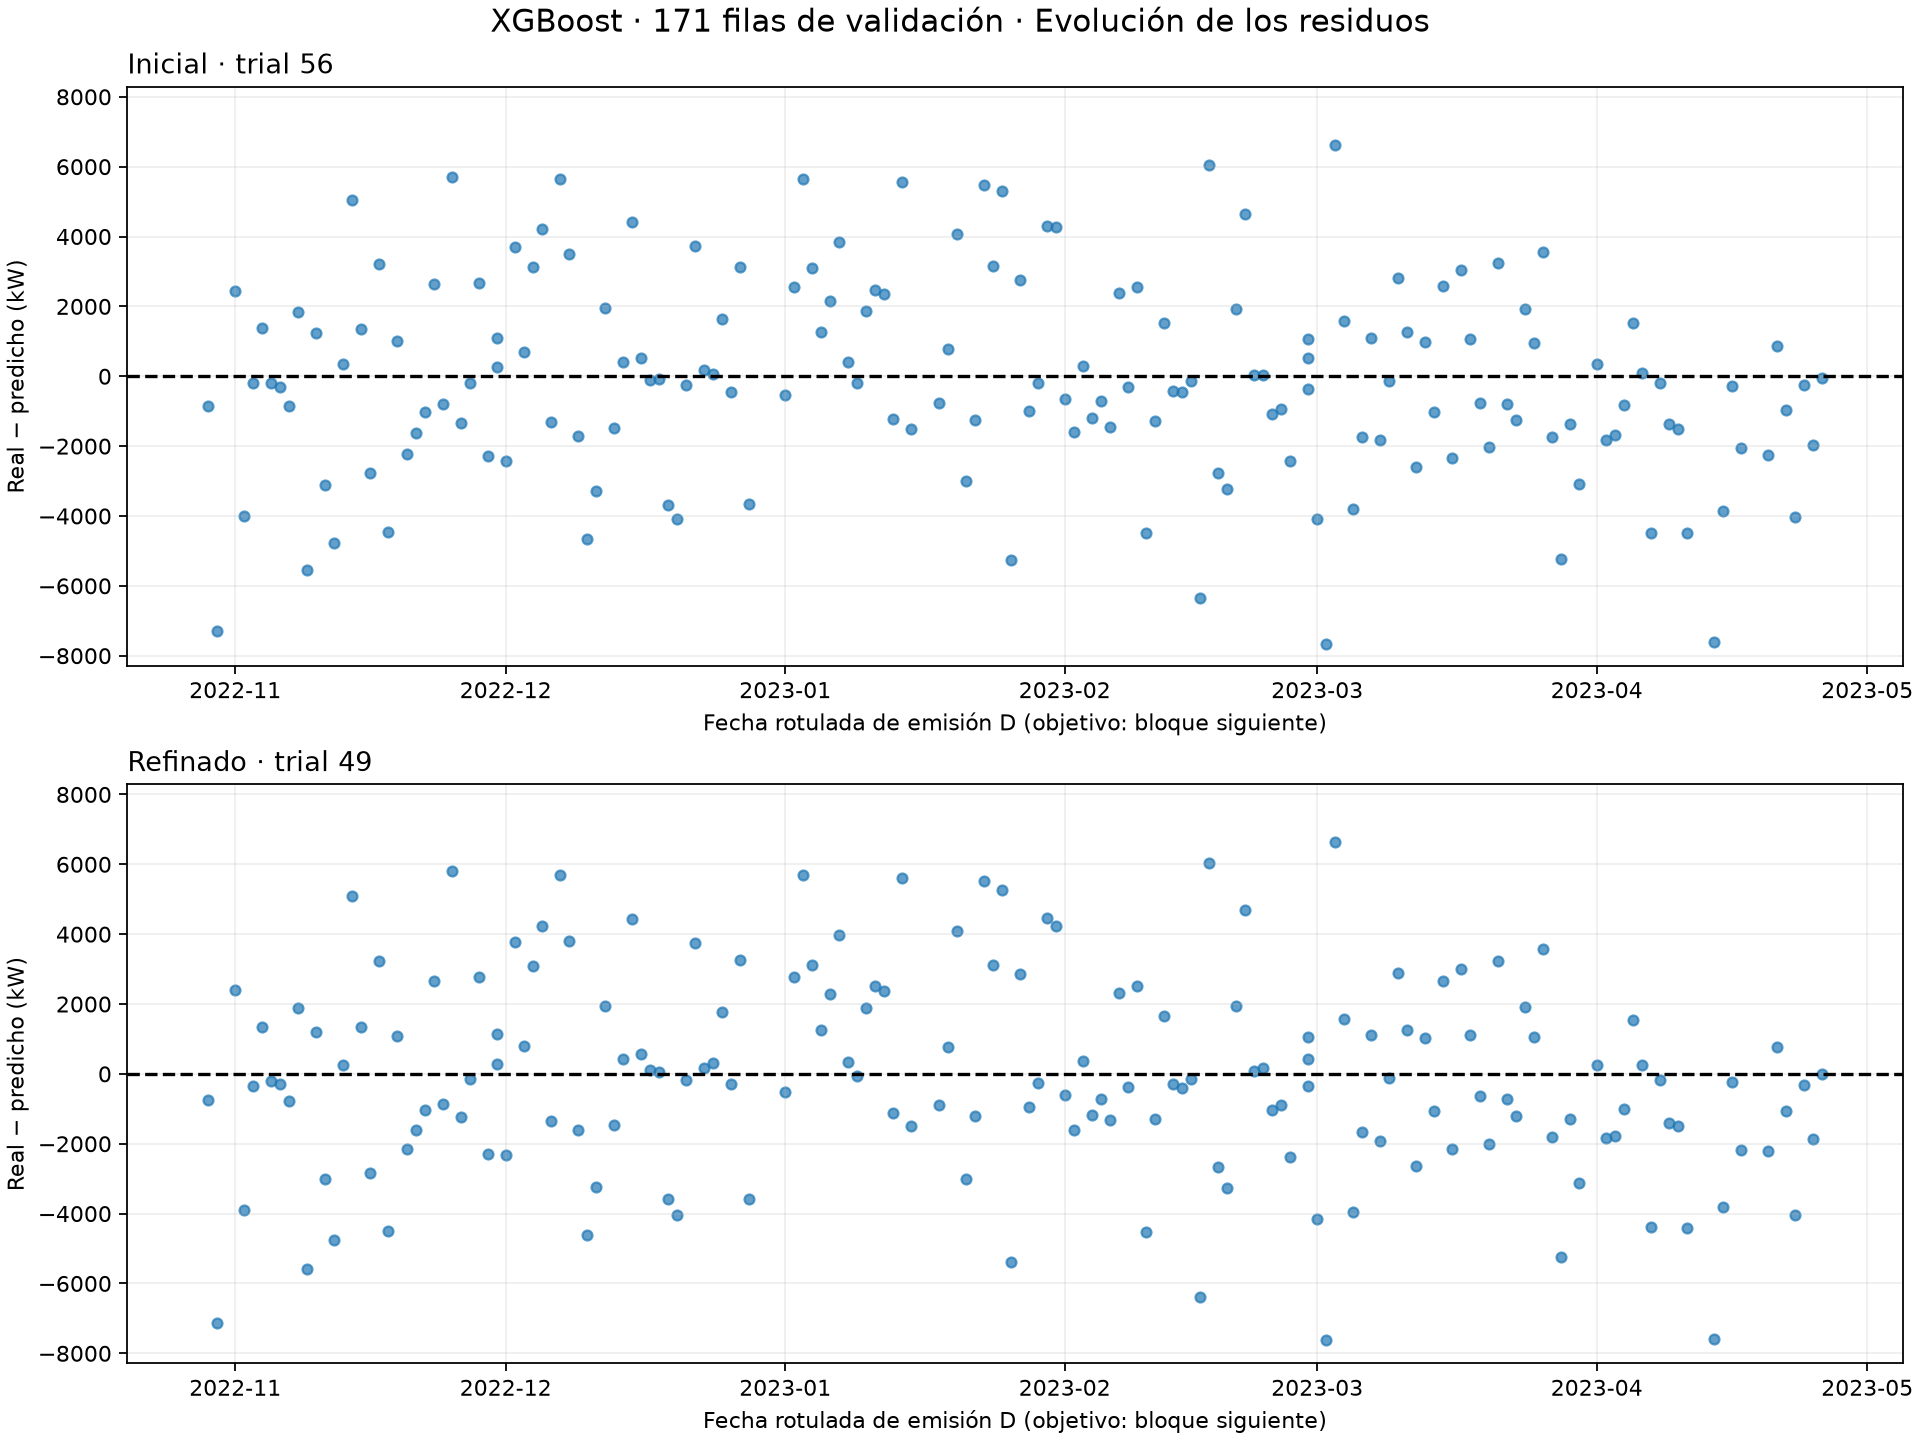

In [7]:
print("Figura. Evolución temporal de residuos")
display(Image(filename=str(carpeta_diagnostico / "residuos_temporales.png")))

Las tablas muestran sesgos por mes y los mayores errores individuales. Los casos extremos se conservan: no se eliminan filas después de conocer su error y no se modifican hiperparámetros a partir de esta inspección.

In [8]:
print("Tabla 26. Sesgo y MAE por mes de emisión, con tamaño de muestra")
display(pd.read_csv(carpeta_diagnostico / "residuos_por_mes.csv").round(3))
print("Tabla 27. Diez errores mayores de cada experimento, identificados por índice CSV")
display(pd.read_csv(carpeta_diagnostico / "errores_mayores.csv").round(3))

Tabla 26. Sesgo y MAE por mes de emisión, con tamaño de muestra


,experimento,mes_emision,filas,sesgo,mae
0,inicial_15,2022-10,2,-4068.973,4068.973
1,inicial_15,2022-11,31,-175.373,2126.614
2,inicial_15,2022-12,28,347.876,2289.021
3,inicial_15,2023-01,29,1599.660,2628.842
4,inicial_15,2023-02,29,-303.075,1755.089
5,inicial_15,2023-03,30,-353.847,2406.715
6,inicial_15,2023-04,22,-1673.616,1928.640
7,refinado_15,2022-10,2,-3950.874,3950.874
8,refinado_15,2022-11,31,-162.414,2130.495
9,refinado_15,2022-12,28,427.176,2303.510


Tabla 27. Diez errores mayores de cada experimento, identificados por índice CSV


,indice_csv,DIA,real,predicho,residuo,error_absoluto,experimento
0,953,2023-03-02,10274.0,17946.621,-7672.621,7672.621,inicial_15
1,994,2023-04-14,13306.0,20901.790,-7595.790,7595.790,inicial_15
2,831,2022-10-30,7714.0,15014.476,-7300.476,7300.476,inicial_15
3,954,2023-03-03,20679.0,14045.513,6633.487,6633.487,inicial_15
4,937,2023-02-16,13416.0,19771.625,-6355.625,6355.625,inicial_15
5,938,2023-02-17,22369.0,16309.373,6059.627,6059.627,inicial_15
6,856,2022-11-25,20494.0,14782.821,5711.179,5711.179,inicial_15
7,869,2022-12-07,21663.0,16001.905,5661.095,5661.095,inicial_15
8,894,2023-01-03,17060.0,11424.653,5635.347,5635.347,inicial_15
9,840,2022-11-09,13477.0,19033.008,-5556.008,5556.008,inicial_15


## 16. Tracking, preservación y conclusiones

La auditoría compara los trials completos archivados y las validaciones con el
log original, sin agregar registros de entrenamiento. Un registro agrupa los
cinco ajustes de un trial completo; los podados quedan en Optuna y JSON. Esta
granularidad deja parcialmente cubierta la lectura literal de cada entrenamiento
de la sección 3.2. No se inventan fechas por pliegue ni métricas finales de podados.
La tabla de controles verifica también que las fuentes siguen intactas.

In [9]:
print("Tabla 28. Auditoría del tracking histórico")
display(pd.DataFrame([{k: v for k, v in verificacion_diagnostico["tracking"].items() if k != "estudios"}]))
controles_diagnostico = dict(verificacion_diagnostico["controles"])
controles_diagnostico["fuentes_siguen_intactas"] = all(
    huella(raiz_diagnostico / ruta) == valor
    for ruta, valor in verificacion_diagnostico["fuentes_sha256"].items())
print("Tabla 29. Controles del diagnóstico offline; todos deben ser verdaderos")
display(pd.Series(controles_diagnostico, name="Cumple").to_frame())
assert all(controles_diagnostico.values()), controles_diagnostico

Tabla 28. Auditoría del tracking histórico


,registros_xgboost,cv_completos,validaciones,campos_y_metricas_verificados,log_original_modificado,cumplimiento_literal_por_ajuste,limite
0,139,137,2,True,False,Parcial,El CSV agrupa cinco ajustes por COMPLETE; los ...


Tabla 29. Controles del diagnóstico offline; todos deben ser verdaderos


,Cumple
metricas_float32_coinciden_con_evaluaciones,True
mismas_171_filas_y_objetivos,True
tracking_complete_y_validaciones_coincide,True
originales_intactos,True
sin_importar_bibliotecas_de_modelado,True
sin_lectura_de_dataset_ni_test,True
fuentes_siguen_intactas,True


### Conclusión

El informe siguiente se genera desde las tablas guardadas e incluye las cifras de
sesgo, dispersión, patrones temporales y errores mayores. Explica las limitaciones
de la comparación y los pendientes de integración. No se eligió un ganador global,
no se reconstruyó un modelo para extraer importancias y no se utilizó prueba.

In [10]:
display(Markdown((carpeta_diagnostico / "informe.md").read_text(encoding="utf-8")))

# Diagnóstico archivado de XGBoost — Fase 3

Fecha del análisis: 15/11/2026. Fuentes: predicciones y evaluaciones de
`results/xgboost_15_validacion/` y `results/xgboost_15_refinado_validacion/`,
estudios exportados de `results/xgboost*/` y `results/experiment_logs.csv`.
No se abrió el dataset ni el conjunto de prueba, no se cargó un estimador y no
se ejecutaron entrenamiento, predicción, optimización ni una nueva evaluación.
Los SHA-256 de las fuentes están en `verificacion.json` y permanecen intactos.

## 1. Convención y comparación

Se conservan las mismas 171 filas e índices CSV de validación, con fecha rotulada
de emisión entre 29/10/2022 y 26/04/2023. DIA identifica el bloque de emisión;
el objetivo corresponde al bloque siguiente, no necesariamente a DIA + 1 físico
debido al desfase del calendario documentado. Las fechas pueden repetirse;
la identidad y el orden se comprueban por indice_csv. No se interpolan las filas
ausentes. La línea temporal une solo observaciones disponibles y no implica
que se haya evaluado cada día intermedio.

El residuo es real menos predicho: positivo significa subestimación y negativo,
sobreestimación. Se presentan tanto el experimento inicial (trial 56) como el
refinado (trial 49), sin elegir al ganador global del trabajo.

El MAE registrado inicial es 2221.76 kW y el refinado,
2229.22 kW. El refinamiento reduce el MAE de validación
cruzada en 16.74 kW, pero aumenta el MAE de
validación en 7.46 kW.
La mejora del inicial frente a la media móvil de 2497.65 kW es
11.05 % en estas filas de validación;
no es un resultado de prueba ni satisface por sí sola la condición de aprobación.
Las tablas completas están en `comparacion_validacion.csv`, `hiperparametros.csv`
y `espacios_busqueda.csv`; incluyen parámetros fijos y optimizados de ambos ganadores.

## 2. Lectura de las predicciones y los residuos

El gráfico `prediccion_vs_real.png` muestra asociación con el consumo observado,
pero también dispersión alrededor de la diagonal. Las predicciones suavizan
algunos cambios bruscos, como se aprecia en `predicciones_temporales.png`.
No hay un ajuste nuevo de una recta ni calibración de las predicciones.

La distribución (`distribucion_residuos.png`) está cerca de cero en promedio:
sesgo inicial -79.93 kW y refinado
-53.41 kW. Eso no implica errores pequeños:
el desvío inicial es 2851.53 kW y el percentil 95 del error
absoluto es 5595.68 kW. El inicial subestima en
76 filas y sobreestima en 95;
el refinado lo hace en 79 y 92.
No se afirma normalidad ni independencia de los residuos.

En `residuos_vs_predicciones.png` los errores no forman una nube completamente
homogénea: visualmente hay predominio de errores negativos en la zona de
predicciones altas. Es un diagnóstico descriptivo, sin una prueba formal de
heterocedasticidad ni una inferencia causal.

El sesgo global oculta diferencias temporales (`residuos_temporales.png`):
en enero de 2023 el inicial subestima 1599.66 kW en promedio sobre
29 filas, mientras que en abril sobreestima 1673.62 kW
sobre 22. Octubre tiene solo dos filas y no permite generalizar
una comparación mensual. `residuos_por_mes.csv` conserva tamaños, MAE y sesgos.

El mayor error inicial es una sobreestimación de 7672.62 kW
en el índice CSV 953, fecha de emisión 2023-03-02:
real 10274.00 y predicho 17946.62 kW. Los diez mayores errores
concentran 16.89 % del error absoluto total.
Se conservan las diez filas de cada experimento en `errores_mayores.csv`, sin
eliminarlas ni atribuirles fallas de planta que las predicciones no pueden probar.

## 3. Optimización, tracking y precisión

La búsqueda inicial vigente conserva 100 trials (47 completos, 53 podados);
el refinado, 60 (45 completos, 15 podados). Ambos usan TPE con semilla 42,
MedianPruner y cinco pliegues temporales con gap=1 sobre entrenamiento.
El refinado se definió con los diez mejores trials anteriores: amplió árboles
a 1750–3000, mantuvo profundidad 3 y tasa 0.0020702351473759497, y acotó peso
de hijos y fracciones de filas/columnas. Se minimizó el MAE conjunto de las
filas comunes, no el promedio no ponderado por pliegue. Ver ADR 0019.

La auditoría contrasta 137 COMPLETE (incluidos 45 históricos de 14 variables)
y dos validaciones con 139 filas propias del log. Compara parámetros completos,
métricas, filas, semilla, commit y timestamps ISO originales; no faltan ni se
duplican esos registros. `auditoria_tracking.csv` es evidencia derivada, no un
reemplazo ni una ampliación retrospectiva de `experiment_logs.csv`.

La sección 3.2 queda parcialmente cubierta bajo su lectura literal: el log guarda
un experimento por COMPLETE, agrupando cinco ajustes; los podados quedan en
Optuna/JSON, sin fila en el CSV. Los timestamps son de registro, no de inicio del
ajuste, y no llevan zona horaria. No hay evidencia para inventar tiempos por
pliegue ni métricas finales de podados. Resolver el contrato futuro corresponde
a la integración, sin modificar las ejecuciones históricas.

Los CSV contienen representaciones decimales de predicciones float32. Las
métricas calculadas sobre esos decimales difieren mínimamente del log; recuperar
float32 reproduce las tres métricas históricas con tolerancia estricta. El cambio
máximo de predicción es 0.00093750 kW.
Los residuos usan los decimales originales; el resumen separa las métricas del CSV
de las columnas terminadas en `_registrado`. No se corrige ningún resultado previo.

## 4. Reproducción y entrega

Con Python 3.12 y las dependencias congeladas, desde la raíz del repositorio:

```powershell
python -B src/diagnostico_xgboost.py
python -B -m pytest tests/test_diagnostico_xgboost.py -q -p no:cacheprovider
```

El primer comando solo deriva CSV, PNG y verificaciones dentro de esta carpeta.
No importa XGBoost, LightGBM, scikit-learn, Optuna ni joblib. El segundo archivo
de pruebas se limita a aritmética, validaciones de evidencia y controles estáticos.
No se autoriza la suite completa, que contiene ajustes de estimadores.
La sección 13 en adelante de `notebooks/modelado_xgboost.ipynb` es autónoma y
consulta este diagnóstico; las primeras secciones son históricas y no deben
ejecutarse para esta revisión. Las dependencias de estado de las celdas históricas
no se certifican como reproducción integral del notebook desde un kernel vacío.

## 5. Alcance y pendientes

Quedan completos para estos candidatos XGBoost los gráficos de predicción frente
a real y el análisis descriptivo de residuos de 3.3, con salidas ejecutadas.
Los cinco PNG y las tablas quedan preparados para integrar al notebook común,
que no se modifica. Se preservan las 15 variables y todos los resultados previos.

No hay un modelo XGBoost serializado del que extraer importancia de variables.
La f-ANOVA existente trata hiperparámetros y no cubre ese requisito. La consigna
pide importancia de variables del mejor modelo global; queda pendiente de su
elección y de un artefacto real. No se reconstruye un estimador para obtenerla.
También quedan para la integración: comparación de todas las familias, selección
por MAE de validación, entrenamiento final con train+validation, versión semántica,
registry, etiqueta Git y punto de entrada común. Todos los pasos que requieren
ejecutar modelos están fuera del alcance autorizado.

La selección previa de variables no está anidada y validación ya fue consultada
en decisiones anteriores. Estos gráficos añaden inspección del mismo período;
no son una nueva estimación independiente ni justifican ajustar hiperparámetros.
Los cambios de sesgo por mes no demuestran causa operativa ni generalización.
